# Retail Sales Time Series Analysis & Forecasting

## 1. Data Understanding

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
# Load dataset
df = pd.read_csv("Time Series - data train.csv")

# Preserve original dataset for comparison
df_raw = df.copy()

# Check dataset
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (3000888, 6)

First 5 Rows:


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         str    
 2   store_nbr    int64  
 3   family       str    
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 196.8 MB


### Key Findings
- Dataset terdiri dari 3.000.888 baris dan 6 kolom.
- Dataset memiliki variabel numerik dan kategorikal yang mencakup informasi tanggal, toko, kategori produk, penjualan, dan promosi.
- Kolom date masih bertipe object sehingga perlu dikonversi menjadi datetime.
- Dataset memerlukan pemeriksaan kualitas data sebelum dilakukan preprocessing dan analisis time series.

## 2. Data Quality Assessment

### 2.1 Missing Values, Duplicates & Date Validation

In [7]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check duplicate IDs
print("\nDuplicate IDs:", df["id"].duplicated().sum())

# Check invalid dates without changing original data
print("\nInvalid Dates:",
      pd.to_datetime(df["date"], errors="coerce").isna().sum())

Missing Values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Duplicate Rows: 0

Duplicate IDs: 0

Invalid Dates: 0


### Key Findings
- Tidak ditemukan missing values pada seluruh 6 kolom dataset.
- Tidak ditemukan duplicate rows maupun duplicate IDs.
- Seluruh nilai tanggal valid dan dapat dikonversi menjadi datetime.
- Secara keseluruhan, dataset memiliki kualitas awal yang baik tanpa masalah missing values maupun duplikasi.


### 2.2 Data Consistency Check

In [9]:
# Check date range
print("Date Range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())

# Check unique categories
print("\nUnique Stores:", df["store_nbr"].nunique())
print("Unique Product Families:", df["family"].nunique())

# Check negative and zero values
print("\nNegative Sales:", (df["sales"] < 0).sum())
print("Zero Sales:", (df["sales"] == 0).sum())
print("Negative Promotions:", (df["onpromotion"] < 0).sum())

# Check duplicate business keys
print("\nDuplicate Date-Store-Family:",
      df.duplicated(
          subset=["date", "store_nbr", "family"]
      ).sum())

# Numerical summary
display(df[["sales", "onpromotion"]].describe())

Date Range:
Start: 2013-01-01
End: 2017-08-15

Unique Stores: 54
Unique Product Families: 33

Negative Sales: 0
Zero Sales: 939130
Negative Promotions: 0

Duplicate Date-Store-Family: 0


,sales,onpromotion
count,3.000888e+06,3.000888e+06
mean,3.577757e+02,2.602770e+00
std,1.101998e+03,1.221888e+01
min,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00
50%,1.100000e+01,0.000000e+00
75%,1.958473e+02,0.000000e+00
max,1.247170e+05,7.410000e+02


### Key Findings
- Dataset mencakup periode 1 Januari 2013 hingga 15 Agustus 2017, dengan 54 toko dan 33 kategori produk.
- Tidak ditemukan nilai negatif pada sales maupun onpromotion, serta tidak terdapat duplikasi kombinasi date, store_nbr, dan family.
- Sebanyak 939.130 observasi (31,30%) memiliki nilai sales sebesar 0, yang berpotensi mencerminkan periode tanpa aktivitas penjualan.
- Rata-rata sales sebesar 357,76 jauh lebih tinggi dibandingkan median sebesar 11, menunjukkan distribusi yang cenderung right-skewed.
- Nilai maksimum sales mencapai 124.717, menunjukkan adanya nilai penjualan ekstrem yang perlu dianalisis lebih lanjut.
- Variabel onpromotion didominasi nilai 0, dengan nilai maksimum mencapai 741.

### 2.3 Outlier Detection

In [12]:
# Create temporary dataset for outlier detection
df_outlier = df.copy()

# Encode date into number of days
df_outlier["date"] = (
    pd.to_datetime(df_outlier["date"]) -
    pd.to_datetime(df_outlier["date"]).min()
).dt.days

# Encode categorical variable
df_outlier["family"] = pd.factorize(
    df_outlier["family"], sort=True
)[0]

# IQR Outlier Detection
results = []

for col in df_outlier.columns:
    Q1 = df_outlier[col].quantile(0.25)
    Q3 = df_outlier[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (df_outlier[col] < lower) |
        (df_outlier[col] > upper)
    ).sum()

    results.append({
        "Column": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Outliers": outliers,
        "Percentage (%)": round(
            outliers / len(df_outlier) * 100, 2
        )
    })

display(pd.DataFrame(results))

,Column,Lower Bound,Upper Bound,Outliers,Percentage (%)
0,id,-1500443.50,4501330.50,0,0.00
1,date,-843.50,2530.50,0,0.00
2,store_nbr,-26.50,81.50,0,0.00
3,family,-16.00,48.00,0,0.00
4,sales,-293.77,489.62,447105,14.90
5,onpromotion,0.00,0.00,611329,20.37


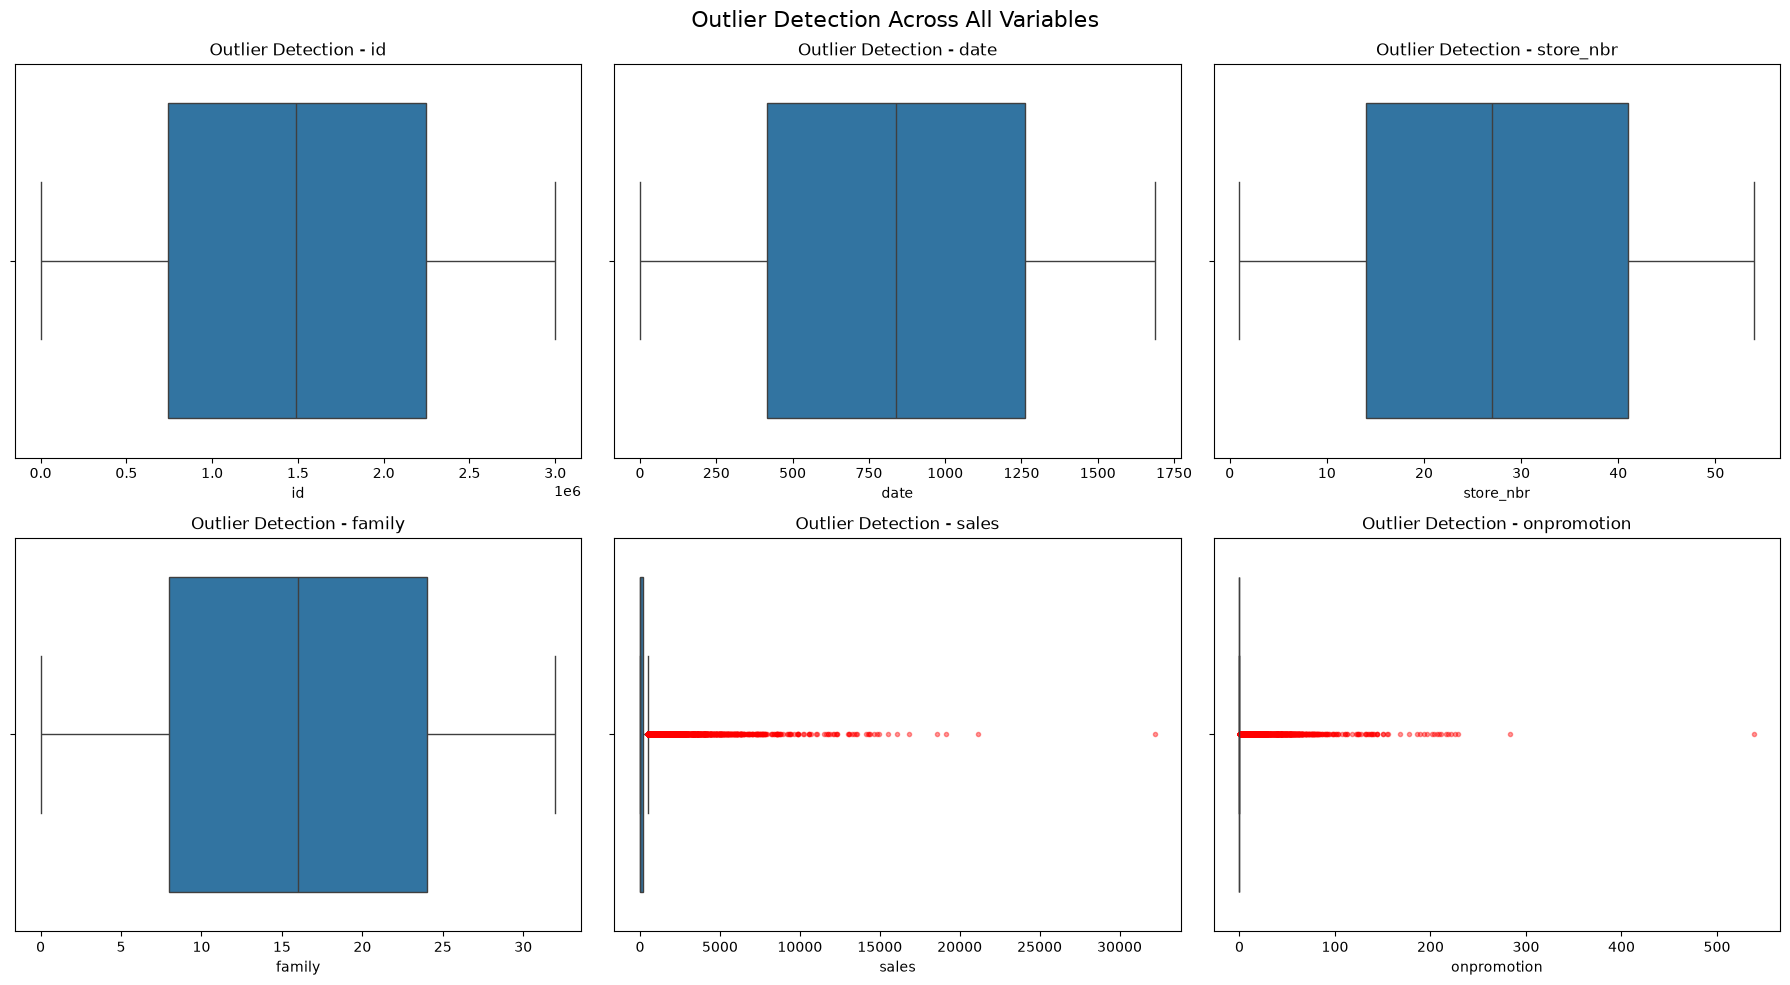

In [13]:
# Sample for visualization only
df_sample = df_outlier.sample(
    n=min(20000, len(df_outlier)),
    random_state=42
)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, col in zip(axes.flatten(), df_sample.columns):
    sns.boxplot(
        x=df_sample[col],
        ax=ax,
        showfliers=True,
        flierprops={
            "marker": "o",
            "markersize": 3,
            "markerfacecolor": "red",
            "markeredgecolor": "red",
            "alpha": 0.4
        }
    )

    ax.set_title(f"Outlier Detection - {col}")
    ax.set_xlabel(col)

plt.suptitle(
    "Outlier Detection Across All Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()


### Key Findings
- Sebanyak 447.105 data (14,90%) teridentifikasi sebagai outlier pada variabel sales.
- Sebanyak 611.329 data (20,37%) teridentifikasi sebagai outlier pada variabel onpromotion.
- Distribusi sales cenderung right-skewed dengan sejumlah nilai ekstrem.
- Outlier pada onpromotion dipengaruhi oleh dominasi nilai nol dalam dataset.
- Tidak ditemukan outlier pada empat variabel lainnya berdasarkan metode IQR, meskipun metode ini tidak relevan secara statistik untuk variabel kategorikal dan identifier.
- Seluruh outlier dipertahankan karena berpotensi mencerminkan aktivitas bisnis yang valid, seperti peningkatan permintaan atau aktivitas promosi.

## 3. Data Cleaning

### 3.1 Data Type Conversion & Standardization

In [16]:
# Create a copy of the raw dataset
df_clean = df_raw.copy()

# Convert date to datetime
df_clean["date"] = pd.to_datetime(df_clean["date"])

# Standardize categorical values
df_clean["family"] = (
    df_clean["family"]
    .str.strip()
    .str.upper()
)

# Compare data types before and after cleaning
dtype_comparison = pd.DataFrame({
    "Before Cleaning": df_raw.dtypes.astype(str),
    "After Cleaning": df_clean.dtypes.astype(str)
})

print("Data Types Comparison:")
display(dtype_comparison)

# Compare dataset dimensions
print("Rows Before:", len(df_raw))
print("Rows After:", len(df_clean))

print("\nColumns Before:", df_raw.shape[1])
print("Columns After:", df_clean.shape[1])

# Display cleaned dataset
print("\nCleaned Dataset:")
display(df_clean.head())

Data Types Comparison:


,Before Cleaning,After Cleaning
id,int64,int64
date,str,datetime64[us]
store_nbr,int64,int64
family,str,str
sales,float64,float64
onpromotion,int64,int64


Rows Before: 3000888
Rows After: 3000888

Columns Before: 6
Columns After: 6

Cleaned Dataset:


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


### Key Findings
- Kolom date berhasil dikonversi dari string menjadi datetime64[us] untuk mendukung analisis time series.
- Kolom family telah melalui standardisasi format menggunakan strip() dan upper().
- Jumlah data tetap 3.000.888 baris dan 6 kolom setelah proses cleaning.
- Tidak ada observasi yang dihapus, termasuk zero sales dan outlier yang sebelumnya teridentifikasi.
- Struktur dataset tetap konsisten dan siap untuk pemeriksaan kelengkapan periode waktu.


### 3.2 Date Continuity & Time Series Validation

In [17]:
# Generate complete daily date range
full_dates = pd.date_range(
    start=df_clean["date"].min(),
    end=df_clean["date"].max(),
    freq="D"
)

# Identify observed dates
actual_dates = pd.DatetimeIndex(
    df_clean["date"].drop_duplicates()
)

# Identify missing calendar dates
missing_dates = full_dates.difference(actual_dates)

print("Expected Dates:", len(full_dates))
print("Actual Unique Dates:", len(actual_dates))
print("Missing Dates:", len(missing_dates))

print("\nMissing Date List:")
print(missing_dates.strftime("%Y-%m-%d").tolist())

# Check number of records per date
daily_records = df_clean.groupby("date").size()

print("\nDaily Record Distribution:")
display(daily_records.describe())


Expected Dates: 1688
Actual Unique Dates: 1684
Missing Dates: 4

Missing Date List:
['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']

Daily Record Distribution:


count    1684.0
mean     1782.0
std         0.0
min      1782.0
25%      1782.0
50%      1782.0
75%      1782.0
max      1782.0
dtype: float64

### Key Findings
- Dataset mencakup 1.688 hari kalender, tetapi hanya 1.684 hari yang memiliki observasi (99,76%).
- Terdapat 4 tanggal yang tidak tercatat, yaitu 25 Desember pada tahun 2013, 2014, 2015, dan 2016.
- Seluruh tanggal yang tersedia memiliki tepat 1.782 observasi per hari, sesuai dengan kombinasi 54 toko dan 33 kategori produk.
- Tidak ditemukan ketidakkonsistenan jumlah observasi pada tanggal yang tersedia.
- Hilangnya data secara berulang pada tanggal 25 Desember mengindikasikan kemungkinan adanya pola operasional atau hari libur, tetapi penyebabnya belum dapat dipastikan.
- Tanggal yang hilang tidak langsung diisi dengan nilai 0 karena tidak adanya observasi belum tentu menunjukkan tidak adanya penjualan.

### 3.3 Daily Sales Aggregation

In [18]:
# Aggregate daily sales
df_daily = df_clean.groupby("date").agg(
    total_sales=("sales", "sum"),
    total_onpromotion=("onpromotion", "sum")
)

# Set daily frequency
df_daily = df_daily.asfreq("D")

# Check aggregation
print("Daily Dataset Shape:", df_daily.shape)

print("\nFirst 5 Rows:")
display(df_daily.head())

print("\nMissing Values After Aggregation:")
print(df_daily.isnull().sum())

# Inspect missing dates
print("\nMissing Date Observations:")
display(df_daily[df_daily["total_sales"].isna()])


Daily Dataset Shape: (1688, 2)

First 5 Rows:


,total_sales,total_onpromotion
date,,
2013-01-01,2511.618999,0.0
2013-01-02,496092.417944,0.0
2013-01-03,361461.231124,0.0
2013-01-04,354459.677093,0.0
2013-01-05,477350.121229,0.0



Missing Values After Aggregation:
total_sales          4
total_onpromotion    4
dtype: int64

Missing Date Observations:


,total_sales,total_onpromotion
date,,
2013-12-25,NaN,NaN
2014-12-25,NaN,NaN
2015-12-25,NaN,NaN
2016-12-25,NaN,NaN



### Key Findings
- Dataset berhasil diagregasi menjadi data penjualan harian dengan 1.688 observasi dan 2 variabel, yaitu total_sales dan total_onpromotion.
- Agregasi dilakukan dengan menjumlahkan penjualan dan promosi dari seluruh toko serta kategori produk berdasarkan tanggal.
- Setelah penerapan frekuensi harian, ditemukan 4 missing values pada masing-masing variabel.
- Missing values terjadi pada tanggal 25 Desember tahun 2013–2016, yang sebelumnya tidak tercatat dalam dataset asli.
- Diperlukan penanganan missing dates agar data memiliki interval waktu yang konsisten untuk analisis time series dan forecasting.


### 3.4 Missing Date Treatment

In [30]:

# Restore daily dataset
df_ts = df_daily.copy()

# Identify missing Christmas dates
df_ts["is_assumed_holiday"] = (
    df_ts["total_sales"].isna() &
    (df_ts.index.month == 12) &
    (df_ts.index.day == 25)
)

# Fill missing Christmas observations with zero
df_ts.loc[
    df_ts["is_assumed_holiday"],
    ["total_sales", "total_onpromotion"]
] = 0

# Update EDA dataset
df_eda = df_ts.copy()

# Validation
print("Dataset Shape:", df_eda.shape)
print("\nMissing Values:")
print(df_eda.isnull().sum())

print("\nChristmas Observations:")
display(df_eda[df_eda["is_assumed_holiday"]])


Dataset Shape: (1688, 3)

Missing Values:
total_sales           0
total_onpromotion     0
is_assumed_holiday    0
dtype: int64

Christmas Observations:


,total_sales,total_onpromotion,is_assumed_holiday
date,,,
2013-12-25,0.0,0.0,True
2014-12-25,0.0,0.0,True
2015-12-25,0.0,0.0,True
2016-12-25,0.0,0.0,True



### Key Findings
- Ditemukan 4 missing dates yang seluruhnya terjadi pada tanggal 25 Desember tahun 2013–2016.
- Pola tersebut diasumsikan berkaitan dengan penutupan operasional toko selama Hari Natal.
- Keempat tanggal diisi dengan nilai sales dan onpromotion sebesar 0 berdasarkan asumsi bisnis.
- Dataset akhir memiliki 1.688 observasi harian dengan interval waktu yang konsisten dan tanpa missing values.
- Seluruh observasi aktual dan outlier tetap dipertahankan.
- Nilai 0 pada Hari Natal merupakan asumsi, bukan data penjualan aktual yang terverifikasi.


## 4. Exploratory Data Analysis (EDA)

### 4.1 Daily Sales Distribution

Daily Sales Descriptive Statistics:


count    1.688000e+03
mean     6.360456e+05
std      2.361766e+05
min      0.000000e+00
25%      4.408053e+05
50%      6.316926e+05
75%      7.855799e+05
max      1.463084e+06
Name: total_sales, dtype: float64


Skewness: 0.376


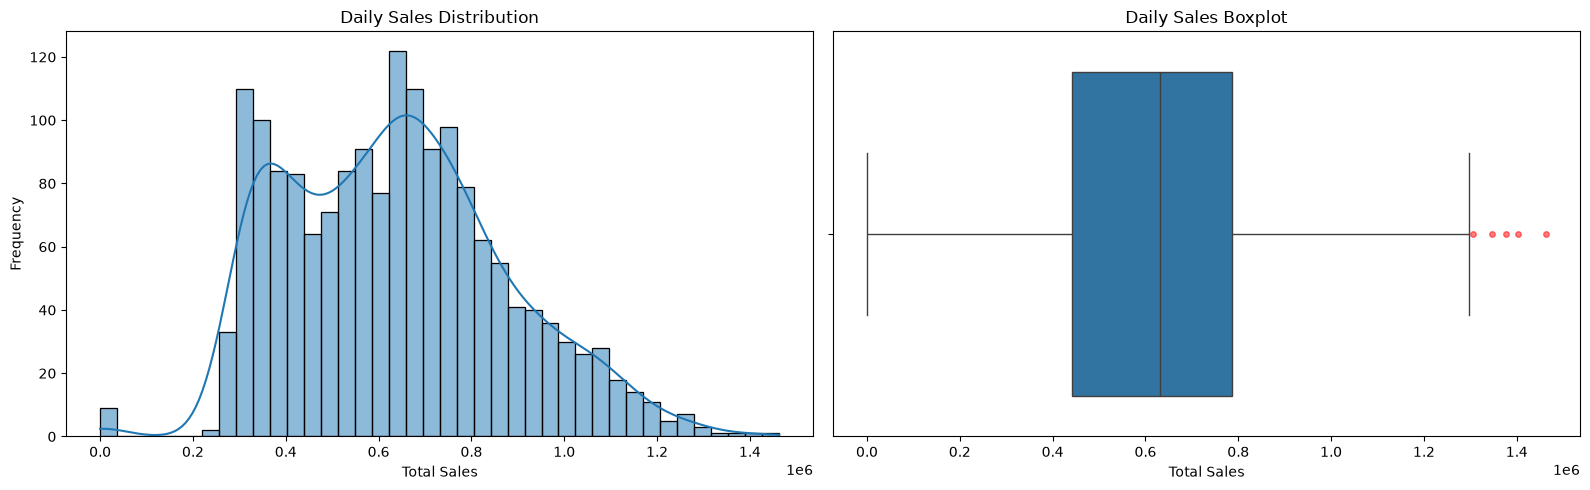

In [31]:

# Daily Sales Descriptive Statistics
print("Daily Sales Descriptive Statistics:")
display(df_eda["total_sales"].describe())

# Calculate skewness
print("\nSkewness:",
      round(df_eda["total_sales"].skew(), 3))

# Visualize Daily Sales Distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Histogram
sns.histplot(
    df_eda["total_sales"],
    bins=40,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Daily Sales Distribution")
axes[0].set_xlabel("Total Sales")
axes[0].set_ylabel("Frequency")

# Boxplot with outliers
sns.boxplot(
    x=df_eda["total_sales"],
    showfliers=True,
    flierprops={
        "marker": "o",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
        "markersize": 4,
        "alpha": 0.5
    },
    ax=axes[1]
)

axes[1].set_title("Daily Sales Boxplot")
axes[1].set_xlabel("Total Sales")

plt.tight_layout()
plt.show()



### Key Findings
- Rata-rata penjualan harian mencapai 636.046 dengan median sebesar 631.693, menunjukkan distribusi yang relatif seimbang.
- Standard deviation sebesar 236.177 menunjukkan adanya variasi penjualan harian yang cukup besar.
- Nilai skewness sebesar 0,376 menunjukkan distribusi sedikit right-skewed.
- Histogram memperlihatkan beberapa konsentrasi penjualan yang berpotensi berkaitan dengan tren atau seasonality.
- Boxplot menunjukkan beberapa outlier dengan nilai penjualan harian mencapai lebih dari 1,3 juta.
- Nilai minimum 0 mencakup empat tanggal Natal yang diasumsikan sebagai hari libur operasional.
- Distribusi belum dapat dinyatakan normal sebelum dilakukan pengujian statistik D'Agostino-Pearson.


### 4.2 Daily Sales Trend & Moving Average

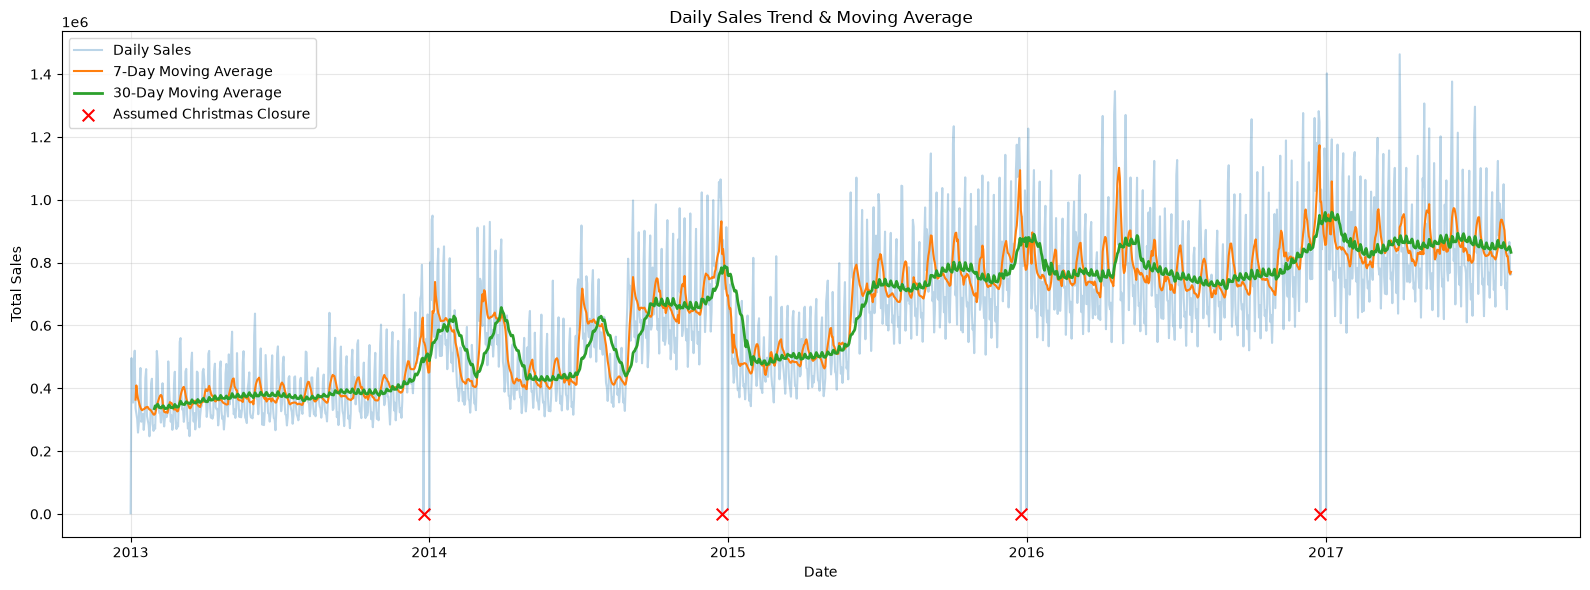

In [32]:

# Calculate Moving Average
df_trend = df_eda.copy()

df_trend["MA_7"] = (
    df_trend["total_sales"].rolling(window=7).mean()
)

df_trend["MA_30"] = (
    df_trend["total_sales"].rolling(window=30).mean()
)

# Visualize Daily Sales Trend
plt.figure(figsize=(16, 6))

plt.plot(
    df_trend.index,
    df_trend["total_sales"],
    label="Daily Sales",
    alpha=0.3
)

plt.plot(
    df_trend.index,
    df_trend["MA_7"],
    label="7-Day Moving Average",
    linewidth=1.5
)

plt.plot(
    df_trend.index,
    df_trend["MA_30"],
    label="30-Day Moving Average",
    linewidth=2
)

# Highlight assumed Christmas holidays
holidays = df_trend[df_trend["is_assumed_holiday"]]

plt.scatter(
    holidays.index,
    holidays["total_sales"],
    color="red",
    marker="x",
    s=70,
    label="Assumed Christmas Closure",
    zorder=5
)

plt.title("Daily Sales Trend & Moving Average")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Key Findings
- Tren penjualan retail secara keseluruhan menunjukkan pertumbuhan positif dari tahun 2013 hingga 2017.
- Moving Average 7 hari menunjukkan fluktuasi jangka pendek, sedangkan Moving Average 30 hari memperlihatkan tren pertumbuhan yang lebih stabil.
- Variabilitas penjualan harian terlihat meningkat pada periode 2015–2017 dibandingkan awal periode pengamatan.
- Terdapat beberapa pola lonjakan dan penurunan penjualan yang berulang, mengindikasikan potensi seasonality.
- Penurunan penjualan hingga 0 pada tanggal 25 Desember berasal dari asumsi penutupan operasional, sementara penurunan tajam pada 1 Januari merupakan observasi aktual.
- Pola tren dan seasonality perlu dianalisis lebih lanjut untuk memahami karakteristik data sebelum forecasting.


### 4.3 Monthly Sales Trend & Growth Rate

Monthly Sales Summary:


,total_sales,MoM_Growth
count,5.500000e+01,54.000000
mean,1.929476e+07,3.429283
std,5.786962e+06,18.589781
min,9.658960e+06,-38.797683
25%,1.334987e+07,-4.447659
50%,2.053164e+07,2.207076
75%,2.392804e+07,10.978479
max,2.964029e+07,69.172516



Highest Sales Month:


,total_sales,days_count,is_complete,MoM_Growth
date,,,,
2016-12-01,2.964029e+07,31,True,20.280487



Lowest Sales Month:


,total_sales,days_count,is_complete,MoM_Growth
date,,,,
2013-02-01,9.658960e+06,28,True,-6.474528


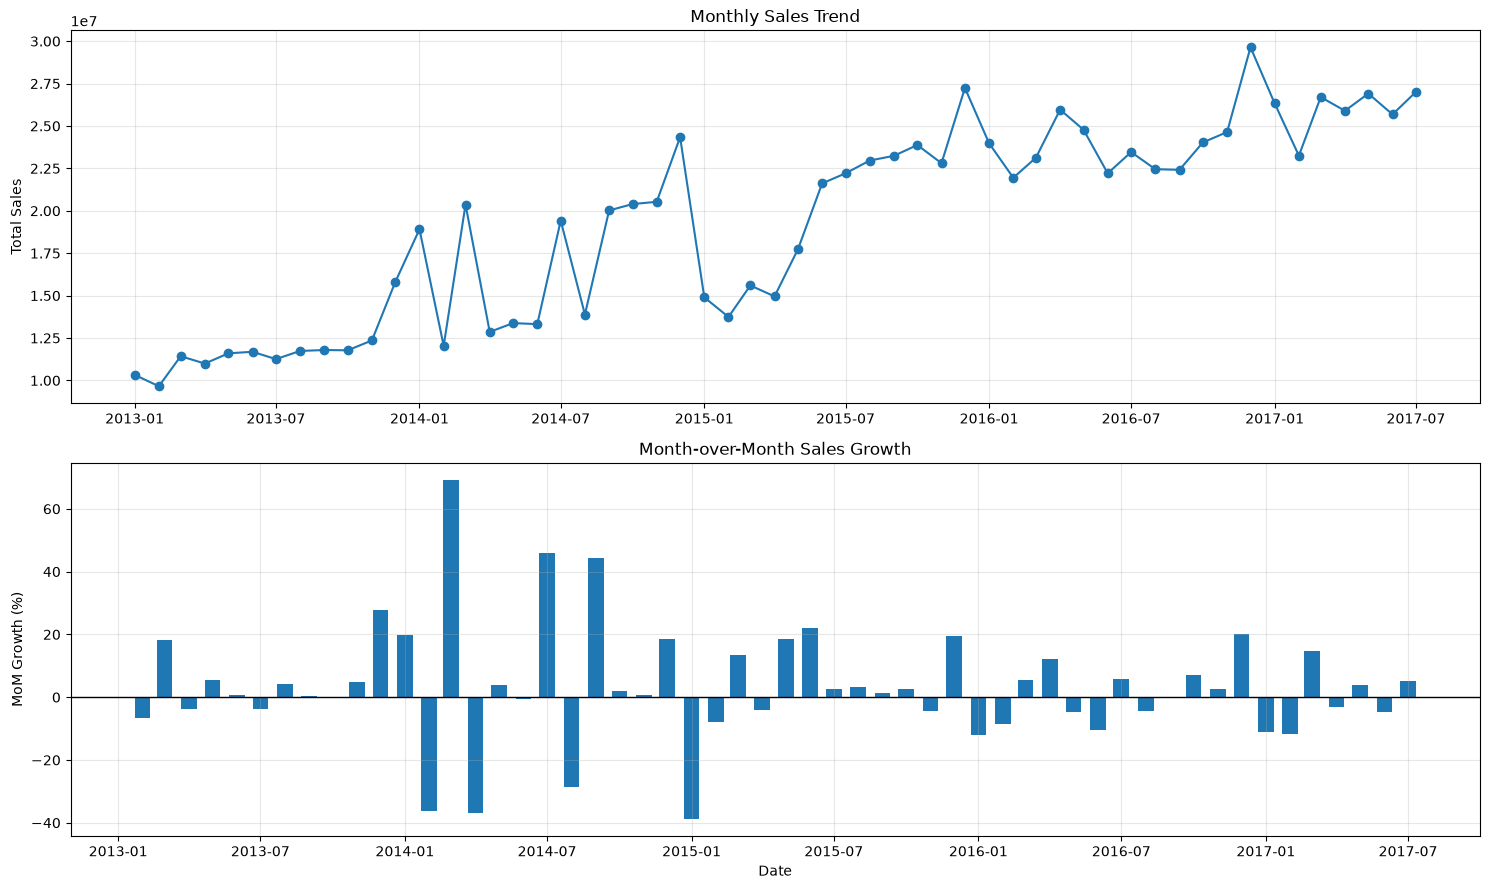

In [33]:

# Aggregate monthly sales
df_monthly = df_eda.resample("MS").agg(
    total_sales=("total_sales", "sum"),
    days_count=("total_sales", "count")
)

# Identify complete months
df_monthly["is_complete"] = (
    df_monthly["days_count"] ==
    df_monthly.index.days_in_month
)

# Use complete months only
df_monthly = df_monthly[
    df_monthly["is_complete"]
].copy()

# Calculate Month-over-Month Growth
df_monthly["MoM_Growth"] = (
    df_monthly["total_sales"].pct_change() * 100
)

# Display statistics
print("Monthly Sales Summary:")
display(df_monthly[
    ["total_sales", "MoM_Growth"]
].describe())

print("\nHighest Sales Month:")
display(df_monthly.nlargest(1, "total_sales"))

print("\nLowest Sales Month:")
display(df_monthly.nsmallest(1, "total_sales"))

# Visualization
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

# Monthly Sales Trend
axes[0].plot(
    df_monthly.index,
    df_monthly["total_sales"],
    marker="o"
)

axes[0].set_title("Monthly Sales Trend")
axes[0].set_ylabel("Total Sales")
axes[0].grid(alpha=0.3)

# Monthly Growth Rate
axes[1].bar(
    df_monthly.index,
    df_monthly["MoM_Growth"],
    width=20
)

axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Month-over-Month Sales Growth")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("MoM Growth (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Key Findings
- Tren penjualan bulanan secara keseluruhan menunjukkan pertumbuhan positif sepanjang periode 2013–2017.
- Penjualan bulanan tertinggi terjadi pada Desember 2016 sebesar 29.640.290, dengan MoM Growth sebesar 20,28%.
- Penjualan bulanan terendah terjadi pada Februari 2013 sebesar 9.658.960, dengan MoM Growth sebesar -6,47%.
- Pertumbuhan bulanan menunjukkan fluktuasi yang cukup besar, terutama sepanjang tahun 2014.
- Penjualan pada periode 2016–2017 cenderung lebih tinggi dan relatif stabil dibandingkan periode sebelumnya.
- Perbedaan jumlah hari antarbulan dapat memengaruhi total sales, sehingga diperlukan analisis rata-rata penjualan harian untuk membandingkan performa secara lebih adil.
- Agustus 2017 dikecualikan karena data hanya tersedia hingga tanggal 15 Agustus.


### 4.4 Weekly Seasonality Analysis

Weekly Sales Statistics:


,mean,median,std
day_of_week,,,
Monday,617542.71,651800.51,202901.45
Tuesday,569926.09,602440.10,199672.00
Wednesday,590782.96,632489.48,210049.76
Thursday,503172.65,530380.85,171443.98
Friday,577169.49,606616.00,195112.78
Saturday,772205.59,816064.64,221747.54
Sunday,821793.98,858897.12,262377.12


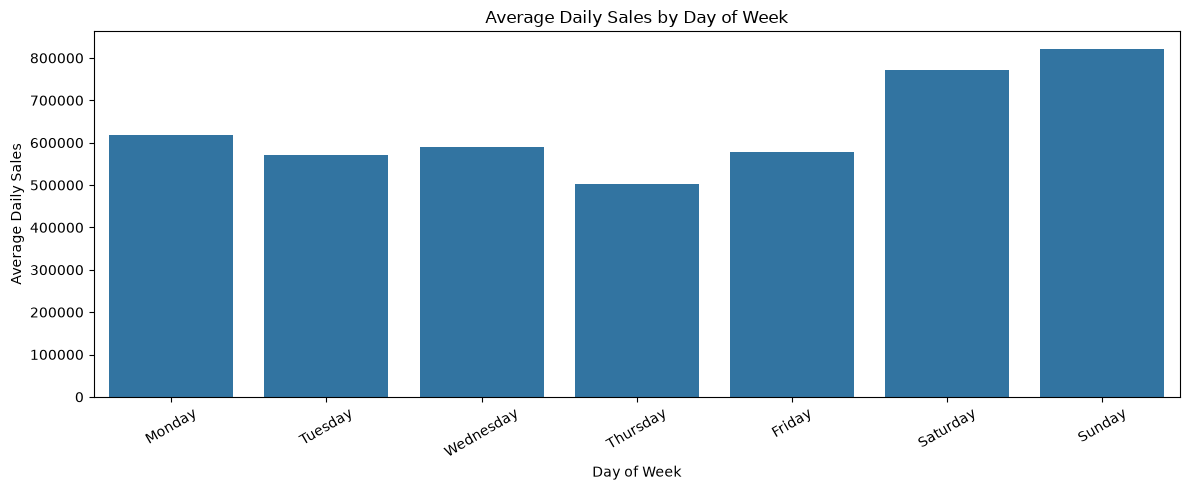

In [35]:
# Create dataset for weekly seasonality
df_weekly = df_eda.copy()

# Extract day of week
df_weekly["day_of_week"] = df_weekly.index.day_name()

# Calculate average daily sales by weekday
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekly_sales = (
    df_weekly.groupby("day_of_week")["total_sales"]
    .agg(["mean", "median", "std"])
    .reindex(weekday_order)
)

print("Weekly Sales Statistics:")
display(weekly_sales.round(2))

# Visualize weekly seasonality
plt.figure(figsize=(12, 5))

sns.barplot(
    data=df_weekly,
    x="day_of_week",
    y="total_sales",
    order=weekday_order,
    errorbar=None
)

plt.title("Average Daily Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



### Key Findings
- Penjualan menunjukkan indikasi weekly seasonality, dengan rata-rata penjualan lebih tinggi pada akhir pekan.
- Sunday mencatat rata-rata penjualan tertinggi sebesar 821.794, sedangkan Thursday terendah sebesar 503.173.
- Rata-rata penjualan weekend sekitar 39,4% lebih tinggi dibandingkan weekday.
- Pola ini mengindikasikan adanya peningkatan aktivitas pembelian pada akhir pekan.
- Weekly seasonality berpotensi menjadi komponen penting dalam pengembangan model forecasting.


### 4.5 Monthly Seasonality Analysis

,Month,Average Daily Sales
0,Jan,609304.21
1,Feb,570574.44
2,Mar,627280.56
3,Apr,604454.12
4,May,609026.69
5,Jun,630111.36
6,Jul,666858.46
7,Aug,572895.60
8,Sep,645614.00
9,Oct,645809.51


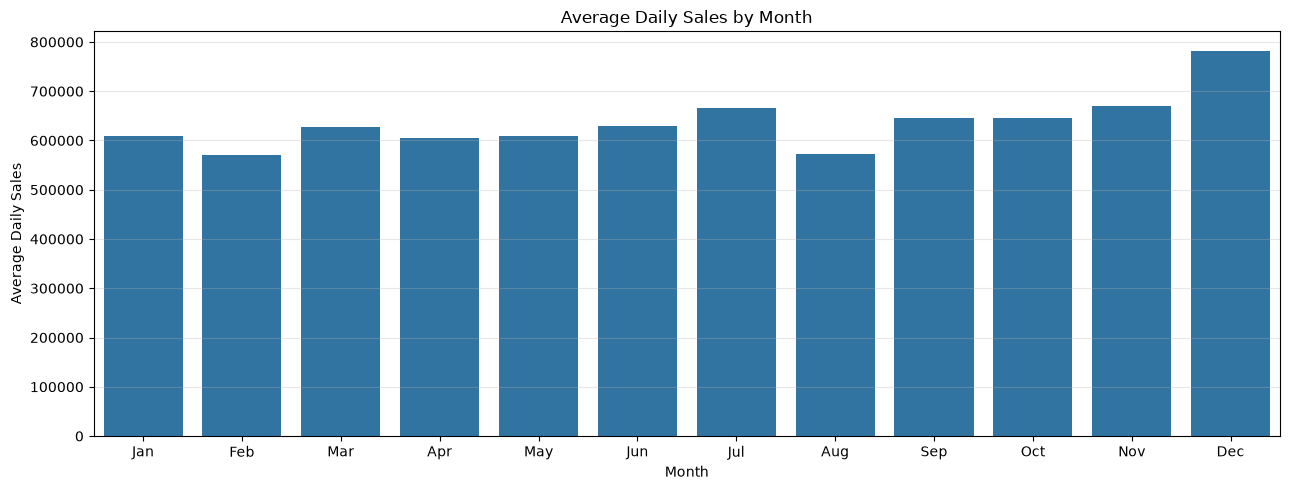

In [36]:

# Calculate average daily sales for each month
df_month_season = df_eda["total_sales"].resample("MS").agg(
    ["sum", "mean", "count"]
)

# Exclude incomplete months
df_month_season = df_month_season[
    df_month_season["count"] ==
    df_month_season.index.days_in_month
].copy()

# Extract month
df_month_season["month"] = df_month_season.index.month

# Calculate monthly seasonal averages
monthly_pattern = (
    df_month_season.groupby("month")["mean"]
    .mean()
)

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

# Display statistics
monthly_summary = pd.DataFrame({
    "Month": month_names,
    "Average Daily Sales": monthly_pattern.values
})

display(monthly_summary.round(2))

# Visualize monthly seasonality
plt.figure(figsize=(13, 5))

sns.barplot(
    data=monthly_summary,
    x="Month",
    y="Average Daily Sales"
)

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### Key Findings
- Desember mencatat rata-rata penjualan harian tertinggi sebesar 782.483, sedangkan Februari terendah sebesar 570.574.
- Rata-rata penjualan harian Desember sekitar 37,1% lebih tinggi dibandingkan Februari.
- November dan Juli juga menunjukkan rata-rata penjualan relatif tinggi, masing-masing sebesar 669.465 dan 666.858.
- Tingginya penjualan pada Desember mengindikasikan potensi year-end seasonality, meskipun belum membuktikan adanya pola musiman yang konsisten.
- Perbedaan jumlah tahun observasi dan tren pertumbuhan dapat memengaruhi hasil, sehingga diperlukan analisis seasonality antar tahun.


### 4.6 Yearly Monthly Seasonality Heatmap

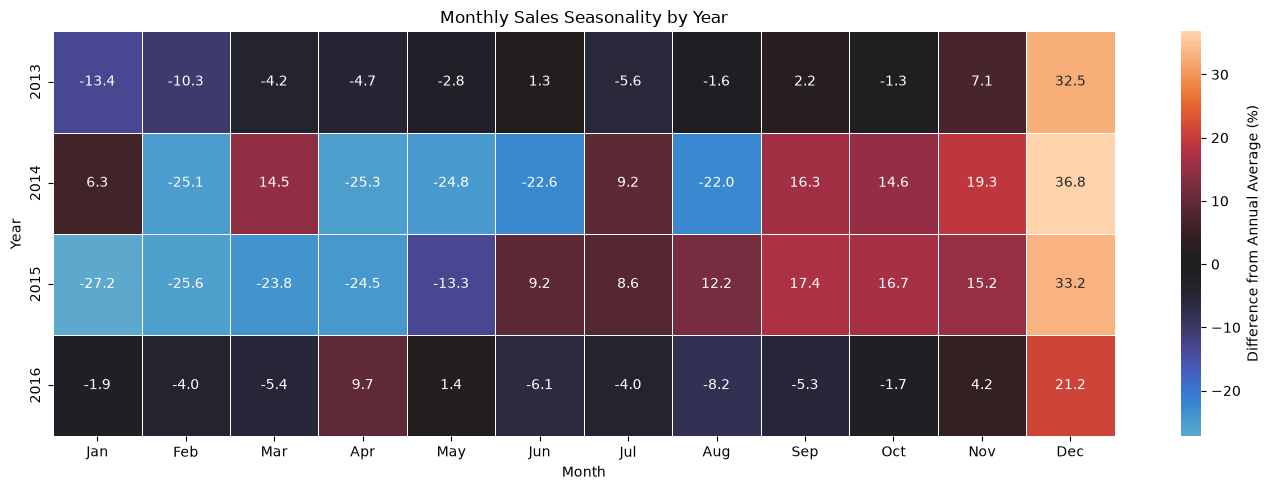

In [37]:

# Use complete years only
df_heatmap = df_eda[
    df_eda.index.year <= 2016
].copy()

# Extract year and month
df_heatmap["year"] = df_heatmap.index.year
df_heatmap["month"] = df_heatmap.index.month

# Calculate annual average daily sales
annual_avg = df_heatmap.groupby(
    "year"
)["total_sales"].mean()

# Calculate monthly average daily sales
monthly_avg = df_heatmap.groupby(
    ["year", "month"]
)["total_sales"].mean().unstack()

# Compare monthly sales with annual average
seasonal_heatmap = (
    monthly_avg.div(annual_avg, axis=0) - 1
) * 100

# Rename months
seasonal_heatmap.columns = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

# Display heatmap
plt.figure(figsize=(14, 5))

sns.heatmap(
    seasonal_heatmap,
    annot=True,
    fmt=".1f",
    center=0,
    linewidths=0.5,
    cbar_kws={
        "label": "Difference from Annual Average (%)"
    }
)

plt.title("Monthly Sales Seasonality by Year")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()



### Key Findings
- Desember secara konsisten mencatat rata-rata penjualan harian tertinggi dibandingkan bulan lainnya sepanjang 2013–2016.
- Performa Desember berada 32,5% (2013), 36,8% (2014), 33,2% (2015), dan 21,2% (2016) di atas rata-rata harian masing-masing tahun.
- November juga menunjukkan performa positif secara konsisten, mengindikasikan potensi peningkatan penjualan menjelang akhir tahun.
- Februari selalu berada di bawah rata-rata penjualan harian tahunan.
- Hasil heatmap mengindikasikan adanya pola year-end seasonality, tetapi pengaruh tren pertumbuhan dalam masing-masing tahun masih perlu diperhitungkan.


### 4.7 Time Series Decomposition

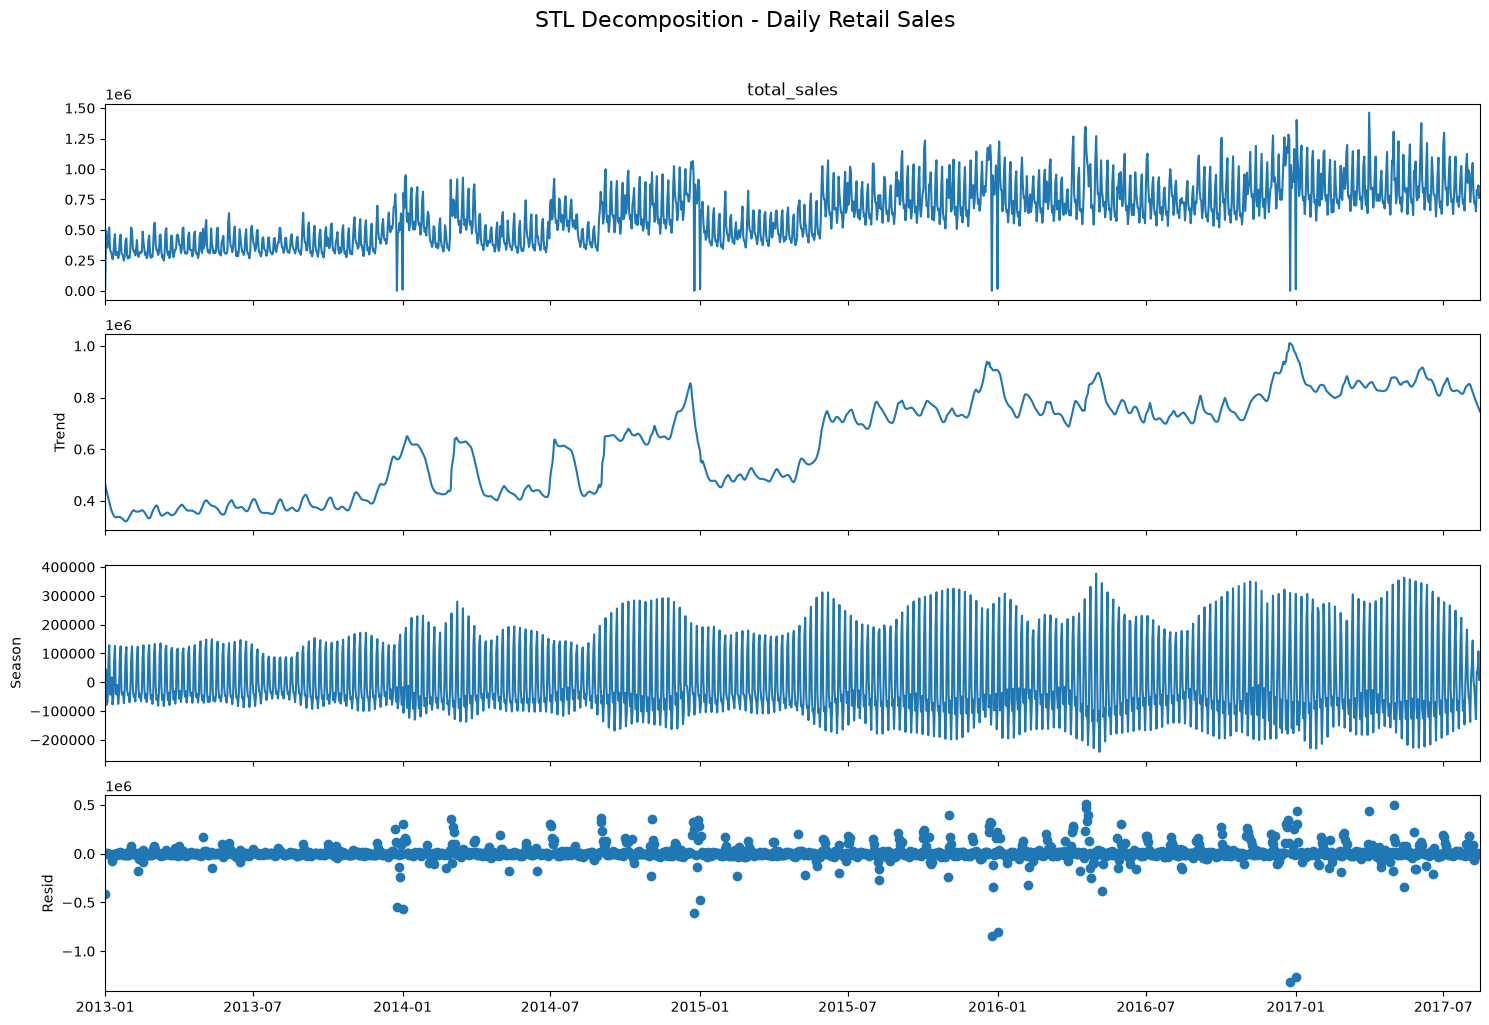

In [38]:

from statsmodels.tsa.seasonal import STL

# STL Decomposition with weekly seasonality
stl = STL(
    df_ts["total_sales"],
    period=7,
    robust=True
)

stl_result = stl.fit()

# Visualize decomposition
fig = stl_result.plot()
fig.set_size_inches(15, 10)

fig.suptitle(
    "STL Decomposition - Daily Retail Sales",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()



### Key Findings
- STL Decomposition menunjukkan tren pertumbuhan penjualan secara keseluruhan sepanjang 2013–2017, meskipun terdapat beberapa periode penurunan.
- Komponen seasonal memperlihatkan pola mingguan yang berulang, mendukung temuan weekly seasonality pada analisis sebelumnya.
- Amplitudo fluktuasi seasonal cenderung meningkat seiring pertumbuhan penjualan.
- Komponen residual masih menunjukkan beberapa penyimpangan ekstrem yang belum dijelaskan oleh trend dan weekly seasonality.
- Penurunan ekstrem di sekitar pergantian tahun berpotensi berkaitan dengan holiday effect, termasuk asumsi penutupan operasional pada 25 Desember.
- Hasil decomposition menunjukkan bahwa penjualan dipengaruhi oleh tren dan pola musiman, sehingga keduanya perlu dipertimbangkan dalam forecasting.


### 4.8 D'Agostino-Pearson Normality Test


Daily Sales
Statistic: 41.3917
P-value: 0.000000
Result: Reject H0 (Not Normally Distributed)

STL Residual
Statistic: 1473.5520
P-value: 0.000000
Result: Reject H0 (Not Normally Distributed)


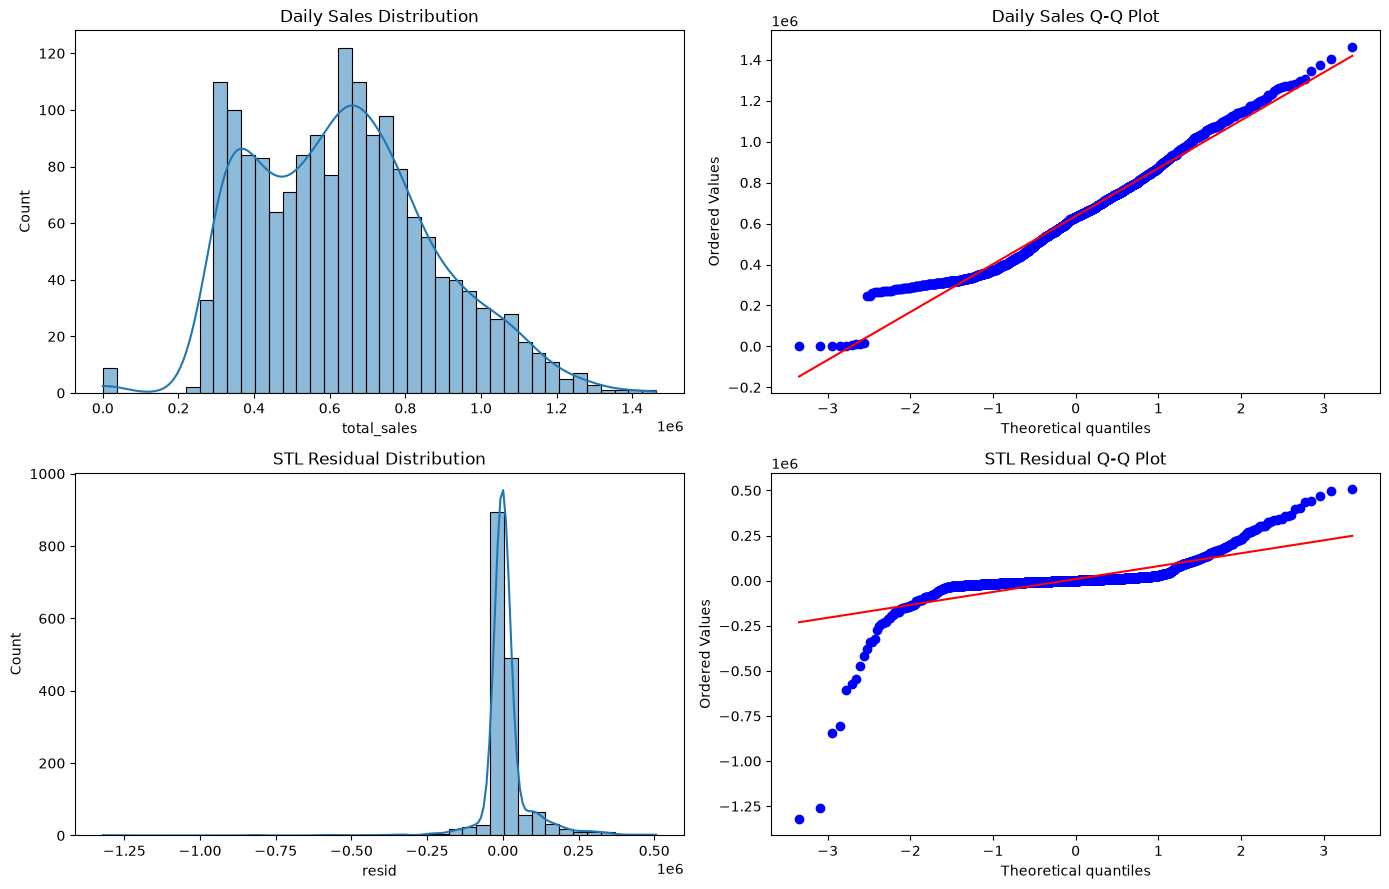

In [39]:

from scipy.stats import normaltest, probplot

# Prepare variables
data_test = {
    "Daily Sales": df_eda["total_sales"],
    "STL Residual": stl_result.resid
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, (name, data) in enumerate(data_test.items()):

    # D'Agostino-Pearson Test
    stat, p_value = normaltest(data)

    print(f"\n{name}")
    print(f"Statistic: {stat:.4f}")
    print(f"P-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Result: Reject H0 (Not Normally Distributed)")
    else:
        print("Result: Fail to Reject H0")

    # Histogram
    sns.histplot(
        data,
        bins=40,
        kde=True,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(f"{name} Distribution")

    # Q-Q Plot
    probplot(
        data,
        dist="norm",
        plot=axes[i, 1]
    )

    axes[i, 1].set_title(f"{name} Q-Q Plot")

plt.tight_layout()
plt.show()



### Key Findings
- D'Agostino-Pearson Test menunjukkan bahwa Daily Sales tidak berdistribusi normal (statistic = 41,3917; p-value < 0,05).
- STL Residual juga tidak berdistribusi normal (statistic = 1.473,5520; p-value < 0,05).
- Q-Q Plot Daily Sales menunjukkan penyimpangan dari distribusi normal, terutama pada bagian ekor.
- Distribusi STL Residual memiliki konsentrasi tinggi di sekitar nol dengan sejumlah nilai ekstrem.
- Hasil pengujian mengindikasikan adanya karakteristik distribusi yang perlu diperhatikan dalam analisis time series.
- Normalitas residual model forecasting akan diuji kembali setelah proses modeling.


### 4.9 ADF Stationarity Test

In [40]:

from statsmodels.tsa.stattools import adfuller

# Augmented Dickey-Fuller Test
adf_result = adfuller(
    df_ts["total_sales"],
    autolag="AIC"
)

print("ADF Statistic:", round(adf_result[0], 4))
print("P-value:", round(adf_result[1], 6))
print("Lags Used:", adf_result[2])
print("Observations:", adf_result[3])

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value:.4f}")

# Interpretation
if adf_result[1] < 0.05:
    print("\nResult: Reject H0")
    print("No significant evidence of a unit root.")
else:
    print("\nResult: Fail to Reject H0")
    print("Unit root cannot be ruled out.")


ADF Statistic: -2.5714
P-value: 0.099051
Lags Used: 22
Observations: 1665

Critical Values:
1%: -3.4343
5%: -2.8633
10%: -2.5677

Result: Fail to Reject H0
Unit root cannot be ruled out.



### Key Findings
- ADF Test menghasilkan statistic sebesar -2,5714 dengan p-value 0,0991.
- Karena p-value > 0,05, H0 gagal ditolak sehingga keberadaan unit root belum dapat dikesampingkan.
- Tren pertumbuhan dan pola musiman yang ditemukan sebelumnya mengindikasikan adanya perubahan karakteristik penjualan sepanjang waktu.
- First Differencing akan dilakukan untuk mengurangi pengaruh tren dan mengevaluasi stationarity data.


### 4.10 First Differencing & Stationarity Re-test

ADF Statistic: -11.3116
P-value: 0.0
Lags Used: 25
Result: Reject H0 - No evidence of unit root


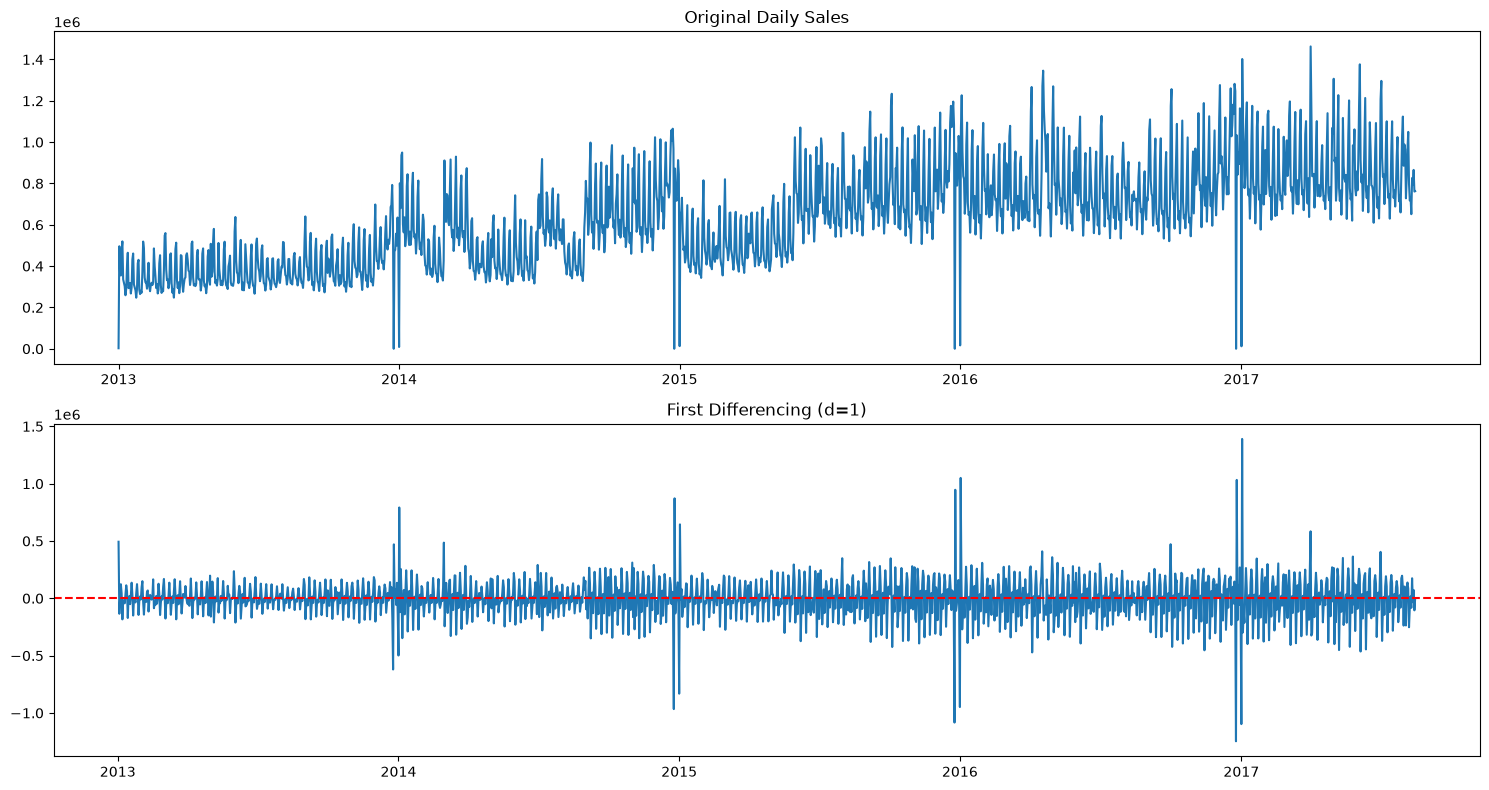

In [41]:

# Apply First Differencing
df_ts["sales_diff_1"] = (
    df_ts["total_sales"].diff()
)

# ADF Test after First Differencing
diff_data = df_ts["sales_diff_1"].dropna()

adf_diff = adfuller(
    diff_data,
    autolag="AIC"
)

print("ADF Statistic:", round(adf_diff[0], 4))
print("P-value:", round(adf_diff[1], 6))
print("Lags Used:", adf_diff[2])

if adf_diff[1] < 0.05:
    print("Result: Reject H0 - No evidence of unit root")
else:
    print("Result: Fail to Reject H0")

# Visualization
fig, axes = plt.subplots(2, 1, figsize=(15, 8))

axes[0].plot(
    df_ts.index,
    df_ts["total_sales"]
)
axes[0].set_title("Original Daily Sales")

axes[1].plot(
    df_ts.index,
    df_ts["sales_diff_1"]
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("First Differencing (d=1)")

plt.tight_layout()
plt.show()



### Key Findings
- ADF Test pada data original menghasilkan p-value 0,0991, sehingga keberadaan unit root belum dapat dikesampingkan.
- Setelah First Differencing, ADF Statistic menjadi -11,3116 dengan p-value < 0,05, sehingga H0 berhasil ditolak.
- First Differencing berhasil mengurangi tren pertumbuhan dan menghasilkan data yang lebih banyak berfluktuasi di sekitar nol.
- Fluktuasi ekstrem masih ditemukan, terutama pada periode pergantian tahun.
- First Differencing (d=1) menjadi kandidat untuk modeling ARIMA/SARIMA, tetapi pola seasonal dan kestabilan varians masih perlu dievaluasi.


### 4.11 ACF & PACF Analysis

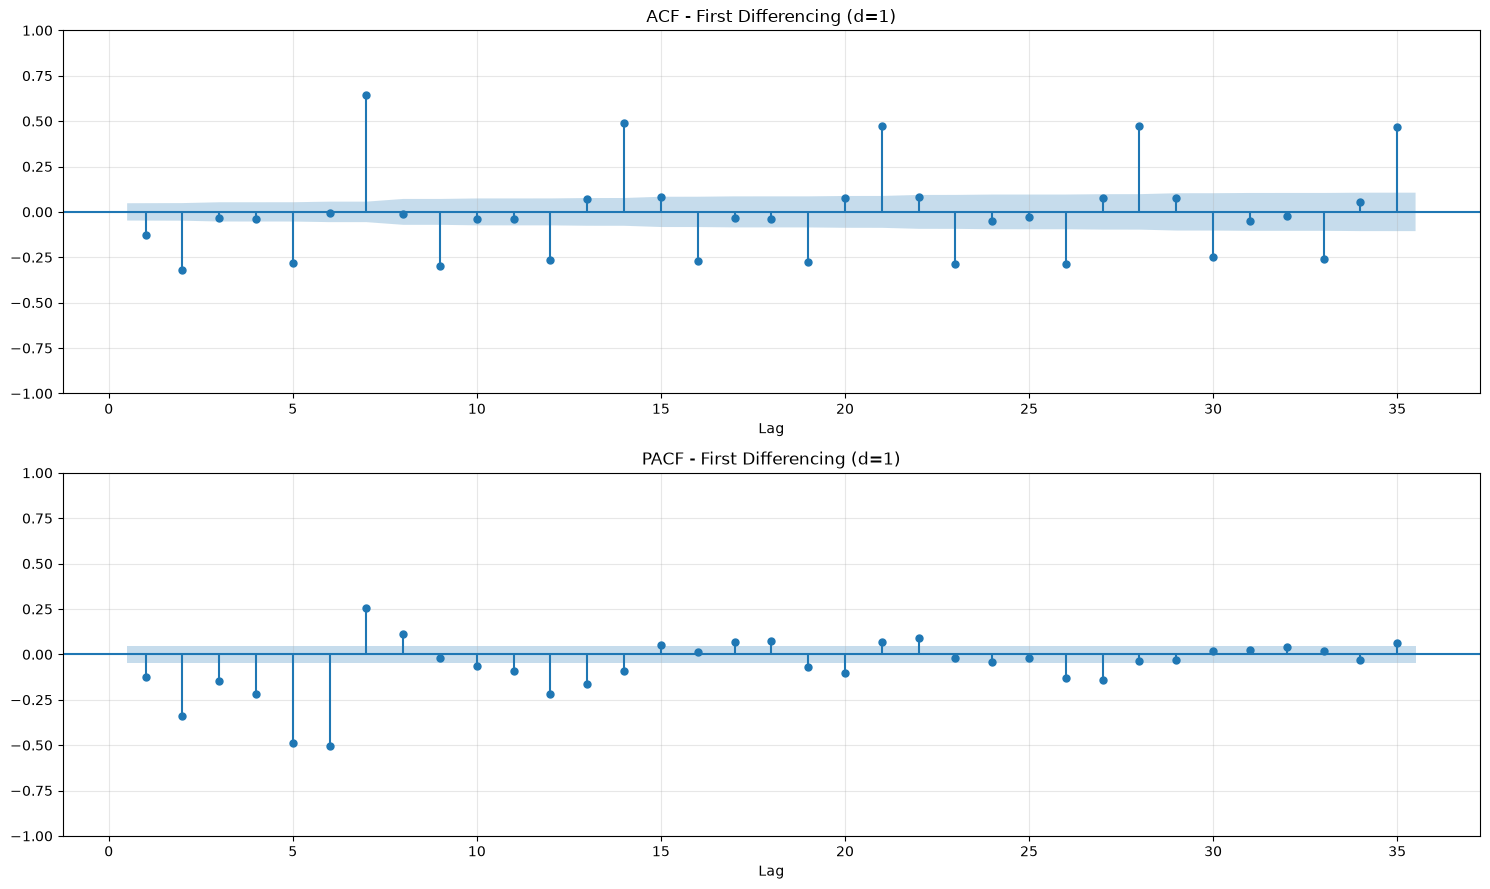

In [42]:

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Use First Differencing data
diff_data = df_ts["sales_diff_1"].dropna()

# Visualize ACF and PACF
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

# ACF Plot
plot_acf(
    diff_data,
    lags=35,
    alpha=0.05,
    zero=False,
    ax=axes[0]
)

axes[0].set_title("ACF - First Differencing (d=1)")
axes[0].set_xlabel("Lag")
axes[0].grid(alpha=0.3)

# PACF Plot
plot_pacf(
    diff_data,
    lags=35,
    alpha=0.05,
    method="ywm",
    zero=False,
    ax=axes[1]
)

axes[1].set_title("PACF - First Differencing (d=1)")
axes[1].set_xlabel("Lag")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Key Findings
- Grafik ACF menunjukkan autokorelasi positif yang kuat pada lag 7, 14, 21, 28, dan 35.
- Pola tersebut mengonfirmasi adanya indikasi weekly seasonality yang kuat dengan periode 7 hari.
- Grafik PACF menunjukkan beberapa lag signifikan, terutama lag 5, 6, dan 7, yang mengindikasikan adanya hubungan autoregressive.
- Meskipun First Differencing telah mengurangi indikasi unit root, pola seasonal masih terlihat jelas.
- Model SARIMA dengan seasonal period (s=7) menjadi kandidat yang relevan untuk forecasting.
- Seasonal Differencing perlu dievaluasi sebelum menentukan parameter akhir model.


### 4.12 Seasonal Differencing & Stationarity Test

ADF Statistic: -12.7464
P-value: 0.0
Lags Used: 22
Result: Reject H0 - No evidence of unit root


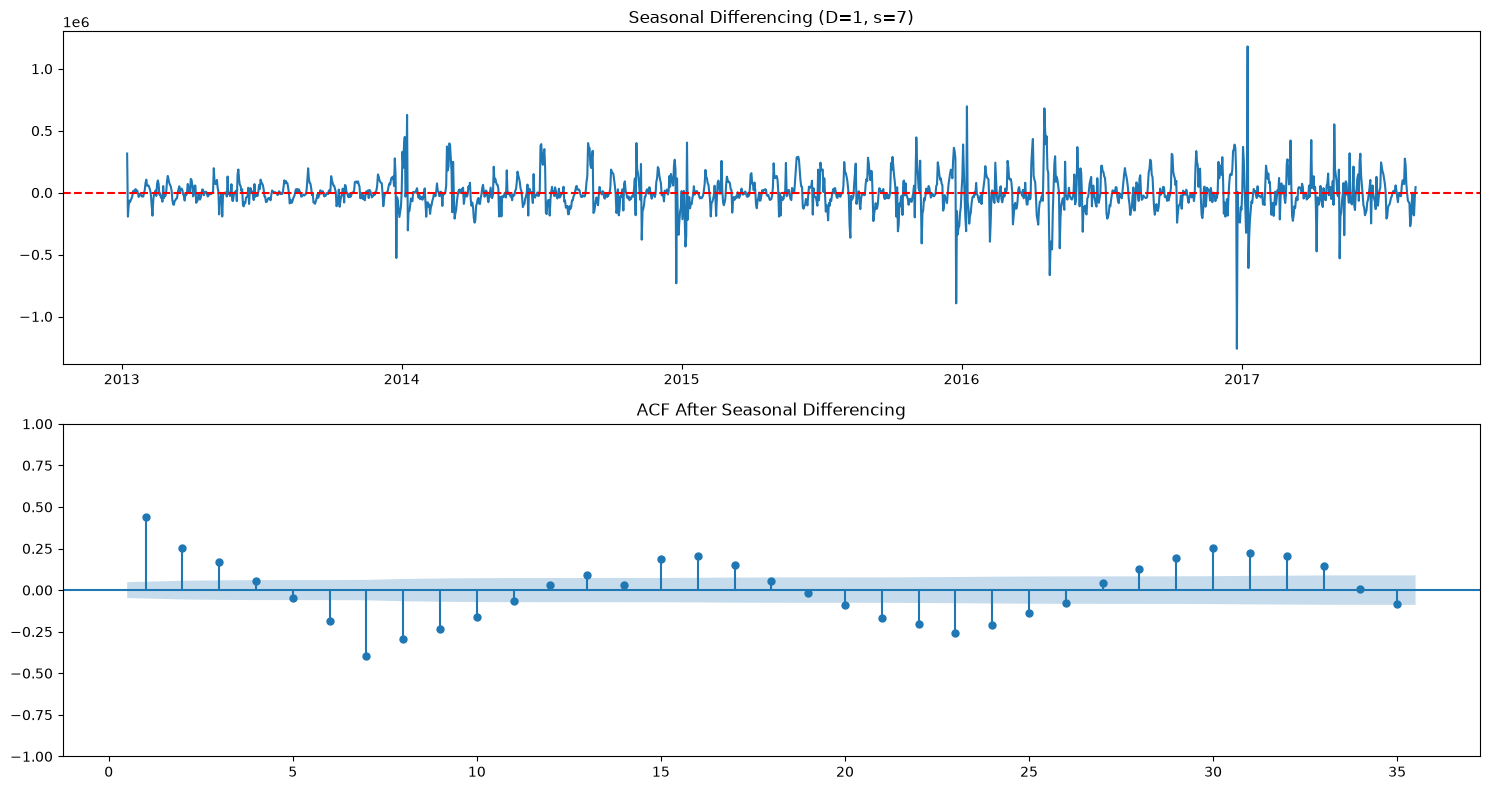

In [44]:

# Apply Seasonal Differencing (s=7)
df_ts["sales_diff_7"] = (
    df_ts["total_sales"].diff(7)
)

seasonal_diff = df_ts["sales_diff_7"].dropna()

# ADF Test after Seasonal Differencing
adf_seasonal = adfuller(
    seasonal_diff,
    autolag="AIC"
)

print("ADF Statistic:", round(adf_seasonal[0], 4))
print("P-value:", round(adf_seasonal[1], 6))
print("Lags Used:", adf_seasonal[2])

if adf_seasonal[1] < 0.05:
    print("Result: Reject H0 - No evidence of unit root")
else:
    print("Result: Fail to Reject H0")

# Visualization
fig, axes = plt.subplots(2, 1, figsize=(15, 8))

axes[0].plot(
    seasonal_diff.index,
    seasonal_diff
)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Seasonal Differencing (D=1, s=7)")

plot_acf(
    seasonal_diff,
    lags=35,
    alpha=0.05,
    zero=False,
    ax=axes[1]
)
axes[1].set_title("ACF After Seasonal Differencing")

plt.tight_layout()
plt.show()



### Key Findings
- Seasonal Differencing (D=1, s=7) menghasilkan ADF Statistic sebesar -12,7464 dengan p-value < 0,05, sehingga H0 berhasil ditolak.
- Data setelah seasonal differencing berfluktuasi di sekitar nol tanpa tren pertumbuhan yang dominan.
- Pola autokorelasi positif berulang pada lag kelipatan 7 mengalami penurunan dibandingkan sebelum seasonal differencing.
- ACF masih menunjukkan autokorelasi signifikan, terutama pada lag 1, 2, dan 7.
- First Differencing dan Seasonal Differencing sama-sama berhasil menolak hipotesis unit root berdasarkan ADF Test.
- Konfigurasi differencing terbaik belum dapat ditentukan hanya berdasarkan ADF Statistic, sehingga diperlukan perbandingan performa forecasting untuk menghindari over-differencing.


### 4.13 Product Family Sales Performance

Top 10 Product Families:


,family,Total_Sales,Average_Sales,Total_OnPromotion,Contribution_Pct
12,GROCERY I,3.434627e+08,3776.97,1914801,31.99
3,BEVERAGES,2.169545e+08,2385.79,906958,20.21
30,PRODUCE,1.227047e+08,1349.35,1117921,11.43
7,CLEANING,9.752129e+07,1072.42,661157,9.08
8,DAIRY,6.448771e+07,709.15,728707,6.01
5,BREAD/BAKERY,4.213395e+07,463.34,331289,3.92
28,POULTRY,3.187600e+07,350.53,226421,2.97
24,MEATS,3.108647e+07,341.85,304028,2.90
25,PERSONAL CARE,2.459205e+07,270.43,246928,2.29
9,DELI,2.411032e+07,265.14,583316,2.25


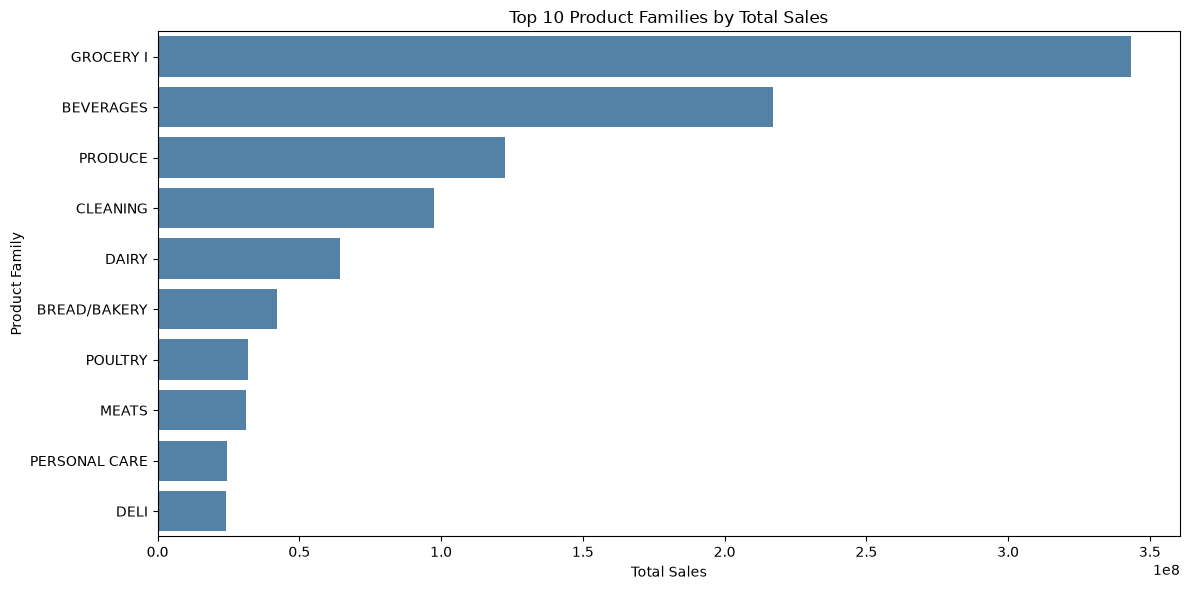

In [69]:

# Aggregate sales by product family
family_summary = (
    df_clean.groupby("family")
    .agg(
        Total_Sales=("sales", "sum"),
        Average_Sales=("sales", "mean"),
        Total_OnPromotion=("onpromotion", "sum")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

# Calculate contribution percentage
family_summary["Contribution_Pct"] = (
    family_summary["Total_Sales"] /
    family_summary["Total_Sales"].sum() * 100
)

# Display Top 10 Families
print("Top 10 Product Families:")
display(family_summary.head(10).round(2))

# Visualize Top 10
plt.figure(figsize=(12, 6))

sns.barplot(
    data=family_summary.head(10),
    x="Total_Sales",
    y="family",
    color="steelblue"
)

plt.title("Top 10 Product Families by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Family")
plt.tight_layout()
plt.show()



### Key Findings
- GROCERY I merupakan kategori dengan total sales tertinggi, diikuti BEVERAGES dan PRODUCE.
- Distribusi penjualan antar kategori menunjukkan konsentrasi yang cukup tinggi pada beberapa kategori utama.
- Terdapat kesenjangan penjualan yang signifikan antara kategori dengan performa tertinggi dan kategori lainnya.
- Kategori dengan volume penjualan tinggi berpotensi menjadi prioritas dalam perencanaan stok dan pengelolaan persediaan.
- Analisis tren dan seasonality berdasarkan kategori diperlukan untuk mengetahui apakah setiap product family memiliki pola permintaan yang sama.


### 4.14 Monthly Sales Trend by Product Family

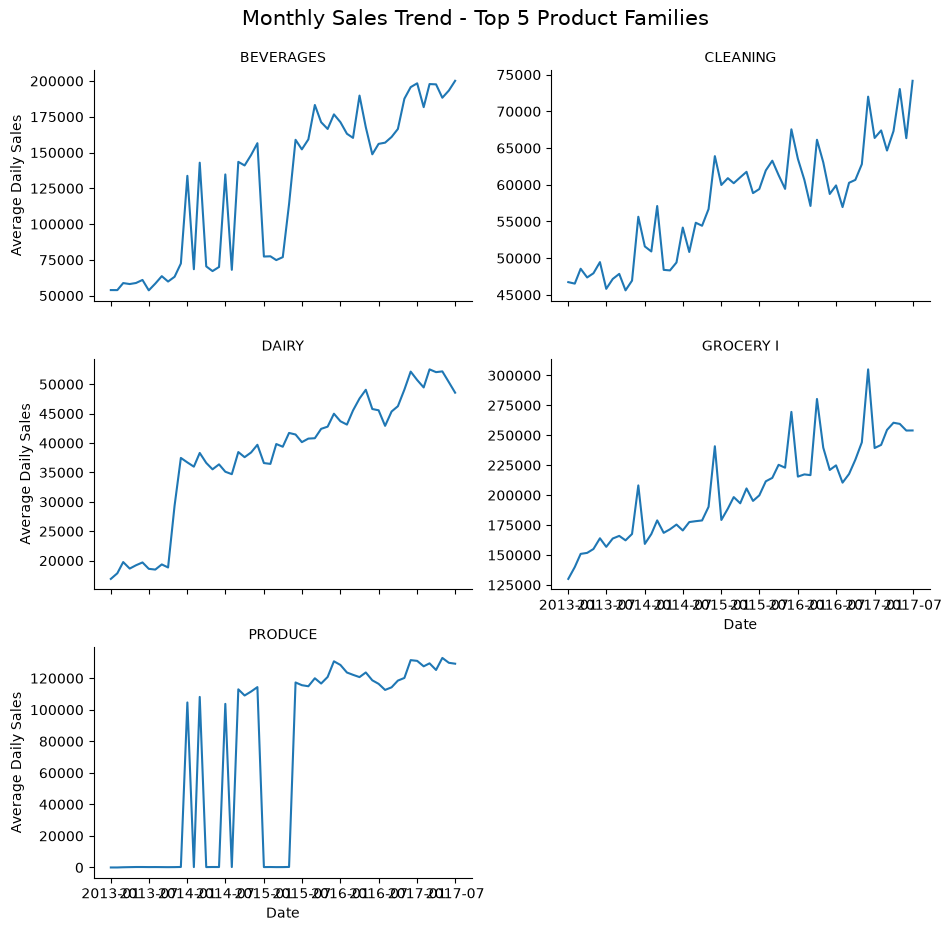

In [75]:

# Select Top 5 Product Families
top5_families = family_summary.head(5)["family"].tolist()

# Monthly aggregation
df_family_monthly = (
    df_clean[df_clean["family"].isin(top5_families)]
    .groupby([
        pd.Grouper(key="date", freq="MS"),
        "family"
    ])["sales"]
    .sum()
    .reset_index()
)

# Exclude incomplete August 2017
df_family_monthly = df_family_monthly[
    df_family_monthly["date"] < "2017-08-01"
].copy()

# Calculate average daily sales per month
df_family_monthly["Avg_Daily_Sales"] = (
    df_family_monthly["sales"] /
    df_family_monthly["date"].dt.days_in_month
)

# Visualize monthly trends
g = sns.relplot(
    data=df_family_monthly,
    x="date",
    y="Avg_Daily_Sales",
    col="family",
    col_wrap=2,
    kind="line",
    height=3,
    aspect=1.6,
    facet_kws={"sharey": False}
)

g.set_axis_labels("Date", "Average Daily Sales")
g.set_titles("{col_name}")
g.figure.suptitle(
    "Monthly Sales Trend - Top 5 Product Families",
    y=1.03,
    fontsize=15
)

plt.show()



### Key Findings
- Lima kategori produk terbesar secara umum menunjukkan tren pertumbuhan penjualan sepanjang periode 2013–2017.
- GROCERY I memiliki rata-rata penjualan harian tertinggi dengan beberapa lonjakan signifikan yang mengindikasikan potensi seasonality.
- BEVERAGES menunjukkan pertumbuhan yang kuat, terutama setelah tahun 2015, tetapi memiliki fluktuasi cukup besar pada periode sebelumnya.
- PRODUCE menunjukkan perubahan pola penjualan yang drastis pada 2014–2015, sehingga perlu investigasi lebih lanjut terkait kemungkinan perubahan operasional atau pencatatan data.
- CLEANING dan DAIRY menunjukkan pola pertumbuhan yang relatif lebih bertahap dan stabil.
- Perbedaan tren antar kategori mengindikasikan bahwa strategi inventory planning perlu mempertimbangkan karakteristik permintaan masing-masing product family.


### 4.15 Promotion vs Sales by Product Family

Promotion vs Sales by Product Family:


,family,Promo_Status,Avg_Sales,Observations
0,BEVERAGES,Non-Promo,1292.27,39231
1,BEVERAGES,Promo,3215.50,51705
2,CLEANING,Non-Promo,868.38,41036
3,CLEANING,Promo,1240.21,49900
4,DAIRY,Non-Promo,479.81,44951
5,DAIRY,Promo,933.34,45985
6,GROCERY I,Non-Promo,2717.72,34050
7,GROCERY I,Promo,4411.00,56886
8,PRODUCE,Non-Promo,792.10,60152
9,PRODUCE,Promo,2438.22,30784


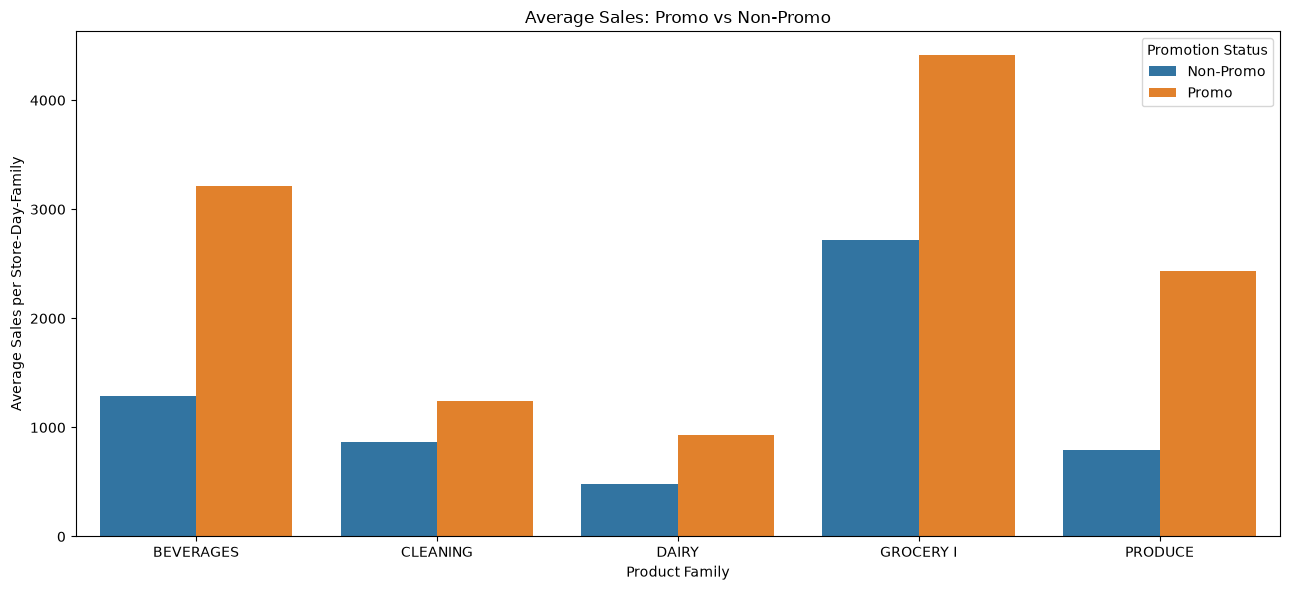

In [71]:

# Select Top 5 Product Families
df_promo = df_clean[
    df_clean["family"].isin(top5_families)
].copy()

# Create promotion status
df_promo["Promo_Status"] = np.where(
    df_promo["onpromotion"] > 0,
    "Promo",
    "Non-Promo"
)

# Calculate average sales by family and promotion
promo_summary = (
    df_promo.groupby(
        ["family", "Promo_Status"],
        observed=True
    )
    .agg(
        Avg_Sales=("sales", "mean"),
        Observations=("sales", "size")
    )
    .reset_index()
)

print("Promotion vs Sales by Product Family:")
display(promo_summary.round(2))

# Visualization
plt.figure(figsize=(13, 6))

sns.barplot(
    data=promo_summary,
    x="family",
    y="Avg_Sales",
    hue="Promo_Status",
    errorbar=None
)

plt.title("Average Sales: Promo vs Non-Promo")
plt.xlabel("Product Family")
plt.ylabel("Average Sales per Store-Day-Family")
plt.legend(title="Promotion Status")
plt.tight_layout()
plt.show()



### Key Findings
- Seluruh lima kategori produk menunjukkan rata-rata sales lebih tinggi ketika promosi aktif dibandingkan tanpa promosi.
- PRODUCE memiliki selisih persentase terbesar sebesar 207,8%, diikuti BEVERAGES sebesar 148,8%.
- GROCERY I mencatat rata-rata sales tertinggi ketika promosi aktif, yaitu 4.411 per observasi.
- CLEANING memiliki selisih rata-rata sales terkecil, yaitu 42,8%.
- Hasil menunjukkan adanya asosiasi positif antara aktivitas promosi dan penjualan, tetapi belum membuktikan hubungan sebab-akibat.
- Diperlukan analisis korelasi dan faktor waktu untuk memahami hubungan antara intensitas promosi dan penjualan secara lebih mendalam.


### 4.16 Promotion vs Sales Correlation Analysis

Daily Correlation: 0.5749
Weekly Correlation: 0.8008


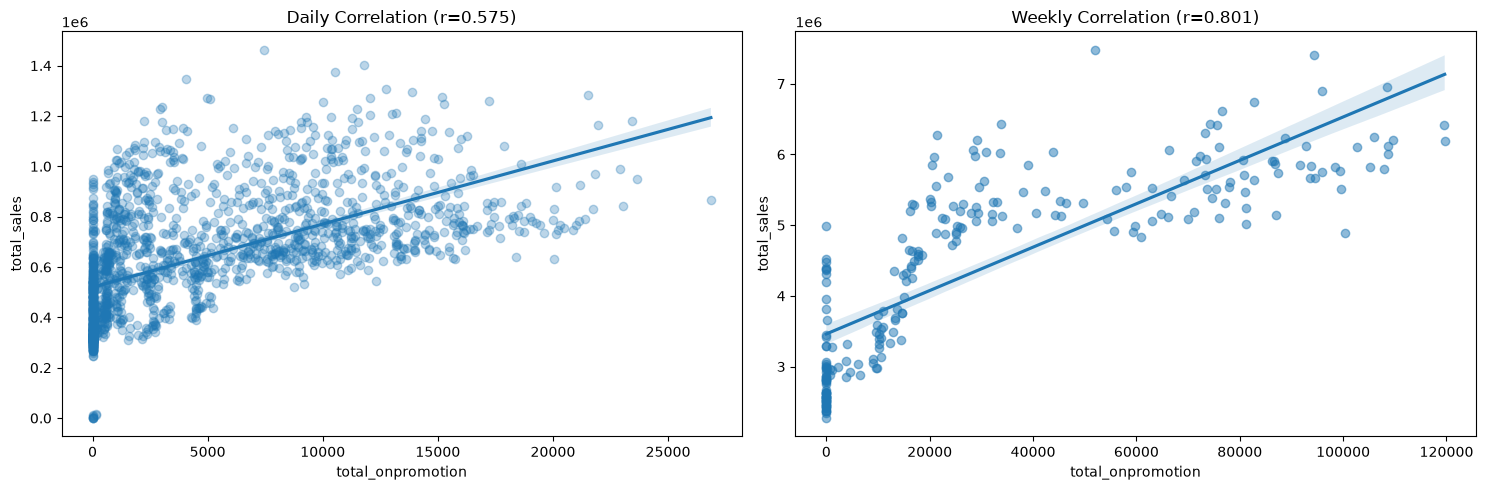

In [72]:

# Daily correlation
daily_corr = df_ts[
    ["total_sales", "total_onpromotion"]
].corr().iloc[0, 1]

# Weekly aggregation
df_weekly_corr = df_ts[
    ["total_sales", "total_onpromotion"]
].resample("W-SUN").sum()

# Keep complete weeks only
week_count = df_ts["total_sales"].resample("W-SUN").count()
df_weekly_corr = df_weekly_corr[week_count == 7]

# Weekly correlation
weekly_corr = df_weekly_corr.corr().iloc[0, 1]

print(f"Daily Correlation: {daily_corr:.4f}")
print(f"Weekly Correlation: {weekly_corr:.4f}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.regplot(
    data=df_ts,
    x="total_onpromotion",
    y="total_sales",
    scatter_kws={"alpha": 0.3},
    ax=axes[0]
)
axes[0].set_title(f"Daily Correlation (r={daily_corr:.3f})")

sns.regplot(
    data=df_weekly_corr,
    x="total_onpromotion",
    y="total_sales",
    scatter_kws={"alpha": 0.5},
    ax=axes[1]
)
axes[1].set_title(f"Weekly Correlation (r={weekly_corr:.3f})")

plt.tight_layout()
plt.show()



### Key Findings
- Korelasi antara promosi dan penjualan pada level harian sebesar 0,5749, menunjukkan hubungan positif sedang.
- Pada level mingguan, korelasi meningkat menjadi 0,8008, menunjukkan hubungan positif kuat.
- Agregasi mingguan menghasilkan pola hubungan yang lebih jelas dibandingkan data harian.
- Minggu dengan jumlah produk promosi lebih tinggi cenderung memiliki total penjualan lebih tinggi.
- Hubungan tersebut dapat dipengaruhi oleh tren pertumbuhan penjualan dan aktivitas promosi sepanjang waktu.
- Korelasi tidak membuktikan hubungan sebab-akibat, sehingga diperlukan pemeriksaan tambahan sebelum menyimpulkan dampak promosi.


### 4.17 Detrended Promotion vs Sales Correlation

Original Weekly Correlation: 0.8008
Differenced Weekly Correlation: 0.0774


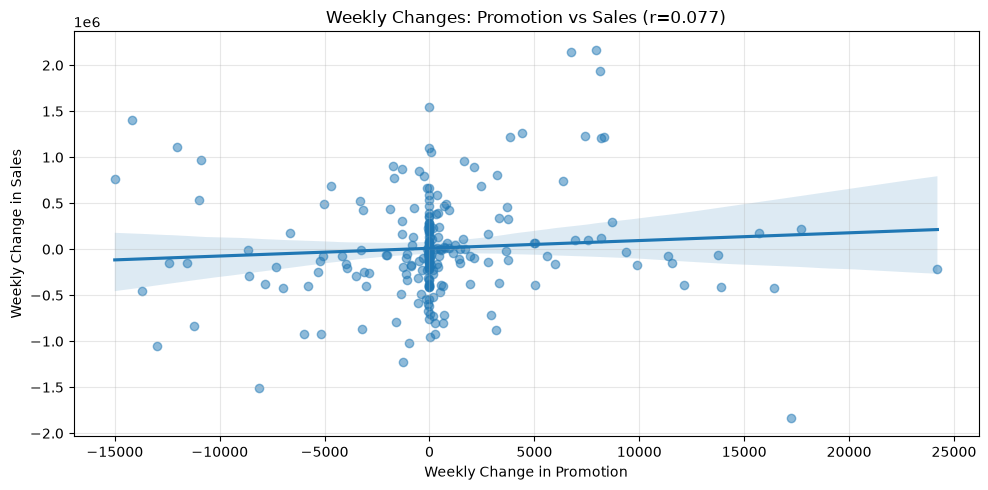

In [73]:

# Calculate weekly changes
df_weekly_diff = df_weekly_corr.diff().dropna()

# Correlation after differencing
diff_corr = df_weekly_diff[
    ["total_sales", "total_onpromotion"]
].corr().iloc[0, 1]

print(f"Original Weekly Correlation: {weekly_corr:.4f}")
print(f"Differenced Weekly Correlation: {diff_corr:.4f}")

# Visualization
plt.figure(figsize=(10, 5))

sns.regplot(
    data=df_weekly_diff,
    x="total_onpromotion",
    y="total_sales",
    scatter_kws={"alpha": 0.5}
)

plt.title(
    f"Weekly Changes: Promotion vs Sales (r={diff_corr:.3f})"
)
plt.xlabel("Weekly Change in Promotion")
plt.ylabel("Weekly Change in Sales")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Key Findings
- Korelasi awal antara promosi dan penjualan mingguan sebesar 0,8008, menunjukkan hubungan positif yang kuat.
- Setelah dilakukan First Differencing, korelasi turun menjadi 0,0774, menunjukkan hubungan linear yang sangat lemah.
- Penurunan korelasi mengindikasikan bahwa tren pertumbuhan bersama kemungkinan berkontribusi terhadap tingginya korelasi awal.
- Perubahan jumlah produk promosi dari minggu ke minggu tidak menunjukkan hubungan linear yang kuat dengan perubahan penjualan pada minggu yang sama.
- Hasil ini tidak membuktikan bahwa promosi tidak efektif, karena pengaruh promosi dapat dipengaruhi oleh faktor waktu, kategori produk, dan variabel lainnya.
- Strategi promosi sebaiknya tidak hanya didasarkan pada korelasi, tetapi juga mempertimbangkan seasonality dan karakteristik permintaan.


## 5. Time Series Forecasting & Modeling

### 5.1 Train-Test Split

Training Observations: 1598
Testing Observations: 90

Training Period:
2013-01-01 00:00:00 to 2017-05-17 00:00:00

Testing Period:
2017-05-18 00:00:00 to 2017-08-15 00:00:00


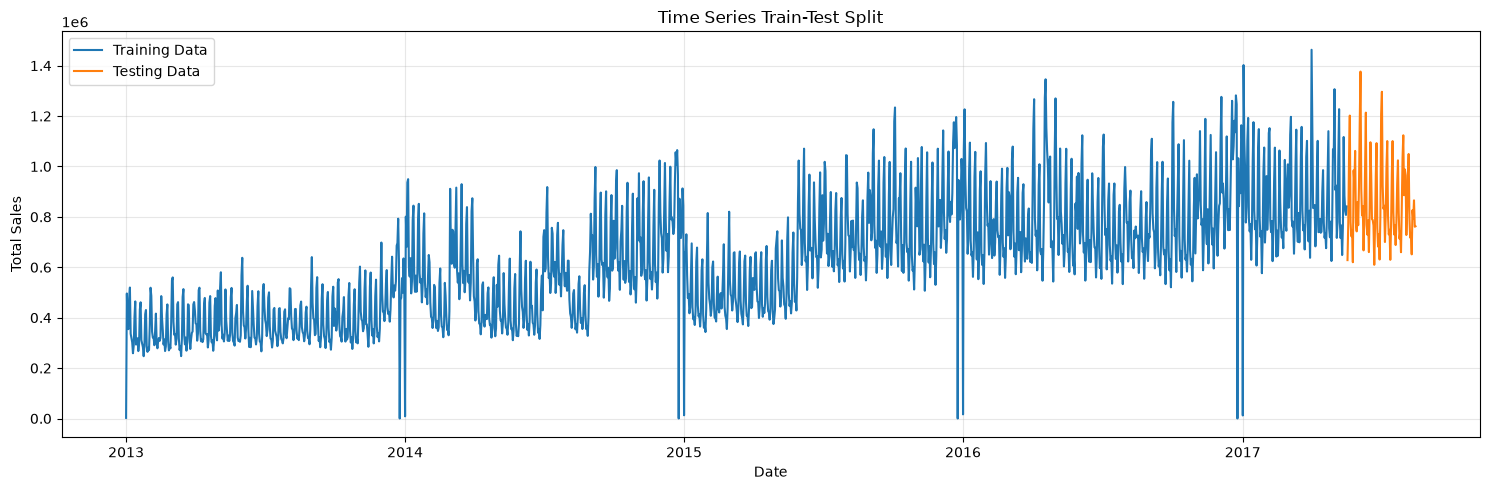

In [46]:

# Prepare original sales data for modeling
ts_data = df_ts["total_sales"].copy()

# Time-based split
train = ts_data.iloc[:-90]
test = ts_data.iloc[-90:]

# Display split information
print("Training Observations:", len(train))
print("Testing Observations:", len(test))

print("\nTraining Period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting Period:")
print(test.index.min(), "to", test.index.max())

# Visualize train-test split
plt.figure(figsize=(15, 5))

plt.plot(
    train.index,
    train,
    label="Training Data"
)

plt.plot(
    test.index,
    test,
    label="Testing Data"
)

plt.title("Time Series Train-Test Split")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Key Findings
- Dataset dibagi secara kronologis menjadi 1.598 observasi training dan 90 observasi testing.
- Training mencakup periode 1 Januari 2013 hingga 17 Mei 2017, sedangkan testing mencakup 18 Mei hingga 15 Agustus 2017.
- Periode testing digunakan untuk mengevaluasi kemampuan model dalam memprediksi penjualan selama 90 hari ke depan.
- Grafik menunjukkan bahwa data testing masih memiliki fluktuasi penjualan yang cukup besar.
- Pembagian data dilakukan tanpa pengacakan untuk menjaga urutan waktu dan menghindari data leakage.


### 5.2 Seasonal Naive Forecasting (Baseline Model)

Seasonal Naive Model Evaluation
MAE: 93,467.95
RMSE: 130,808.95


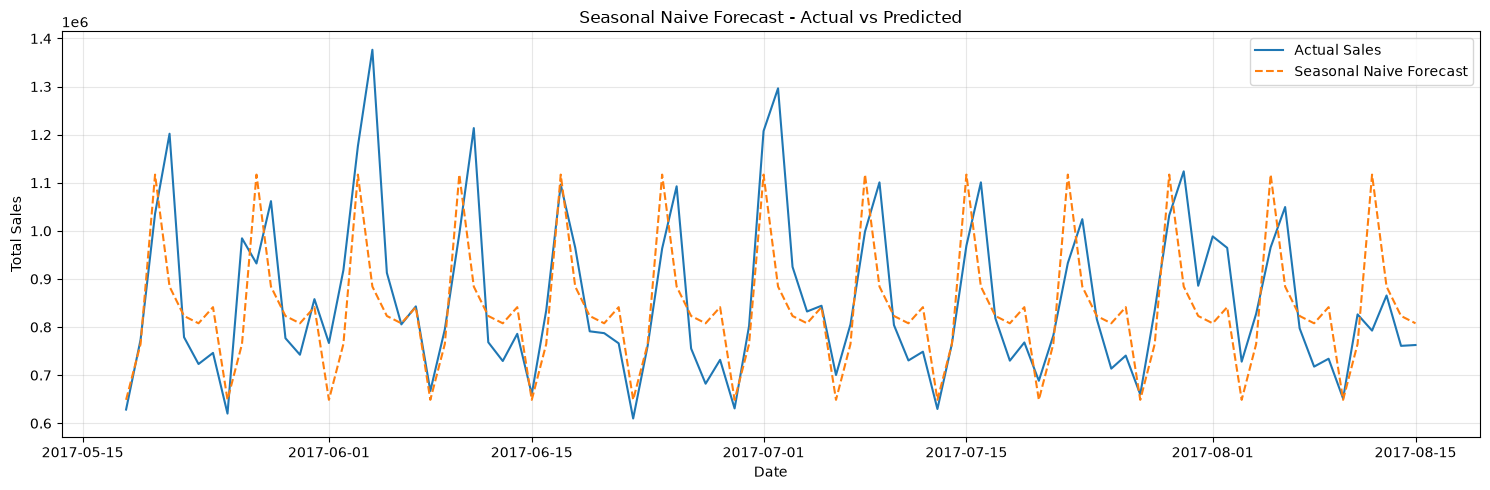

In [48]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Seasonal Naive Forecasting (s=7)
season_length = 7

# Get the last 7 observations from training data
last_week = train.iloc[-season_length:].values

# Repeat the weekly pattern for 90 days
seasonal_naive_forecast = np.tile(
    last_week,
    int(np.ceil(len(test) / season_length))
)[:len(test)]

# Convert forecast to Series
baseline_forecast = pd.Series(
    seasonal_naive_forecast,
    index=test.index
)

# Model Evaluation
baseline_mae = mean_absolute_error(
    test, baseline_forecast
)

baseline_rmse = np.sqrt(
    mean_squared_error(test, baseline_forecast)
)

print("Seasonal Naive Model Evaluation")
print(f"MAE: {baseline_mae:,.2f}")
print(f"RMSE: {baseline_rmse:,.2f}")

# Visualize Actual vs Forecast
plt.figure(figsize=(15, 5))

plt.plot(
    test.index,
    test,
    label="Actual Sales"
)

plt.plot(
    baseline_forecast.index,
    baseline_forecast,
    label="Seasonal Naive Forecast",
    linestyle="--"
)

plt.title("Seasonal Naive Forecast - Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Key Findings
- Seasonal Naive Model menghasilkan MAE sebesar 93.467,95 dan RMSE sebesar 130.808,95.
- Model mampu menangkap pola fluktuasi penjualan mingguan dengan mengulang pola 7 hari terakhir dari training data.
- Beberapa lonjakan penjualan aktual belum berhasil diprediksi secara akurat.
- RMSE yang lebih tinggi dibandingkan MAE mengindikasikan adanya beberapa kesalahan prediksi yang relatif besar.
- Hasil Seasonal Naive digunakan sebagai baseline untuk mengevaluasi apakah model ARIMA dan SARIMA mampu memberikan akurasi forecasting yang lebih baik.


### 5.3 ARIMA Modeling

ARIMA(1,1,1) Model Evaluation
MAE: 134,816.03
RMSE: 164,138.51


,Model,MAE,RMSE
0,Seasonal Naive,93467.95,130808.95
1,"ARIMA(1,1,1)",134816.03,164138.51


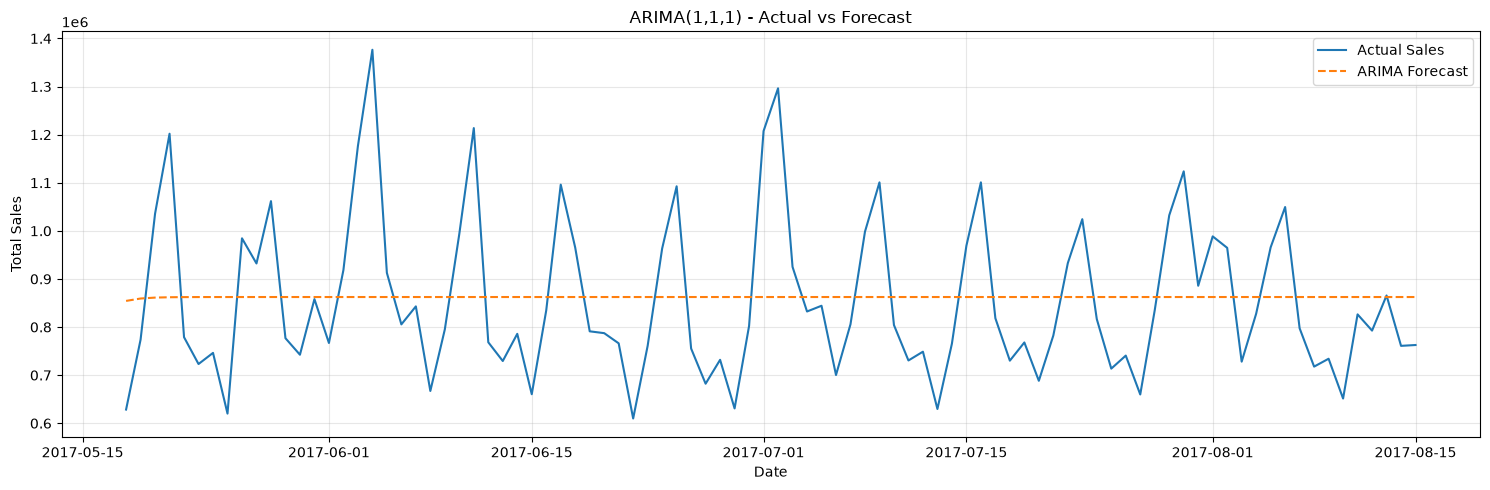

In [49]:

from statsmodels.tsa.arima.model import ARIMA

# Build ARIMA Model
arima_model = ARIMA(
    train,
    order=(1, 1, 1)
)

# Fit model
arima_result = arima_model.fit()

# Forecast next 90 days
arima_forecast = arima_result.forecast(
    steps=len(test)
)

# Model Evaluation
arima_mae = mean_absolute_error(
    test, arima_forecast
)

arima_rmse = np.sqrt(
    mean_squared_error(test, arima_forecast)
)

print("ARIMA(1,1,1) Model Evaluation")
print(f"MAE: {arima_mae:,.2f}")
print(f"RMSE: {arima_rmse:,.2f}")

# Compare with Baseline
comparison = pd.DataFrame({
    "Model": ["Seasonal Naive", "ARIMA(1,1,1)"],
    "MAE": [baseline_mae, arima_mae],
    "RMSE": [baseline_rmse, arima_rmse]
})

display(comparison.round(2))

# Actual vs Forecast
plt.figure(figsize=(15, 5))

plt.plot(
    test.index, test,
    label="Actual Sales"
)

plt.plot(
    arima_forecast.index, arima_forecast,
    label="ARIMA Forecast",
    linestyle="--"
)

plt.title("ARIMA(1,1,1) - Actual vs Forecast")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Key Findings
- ARIMA(1,1,1) menghasilkan MAE sebesar 134.816,03 dan RMSE sebesar 164.138,51.
- Performa ARIMA lebih rendah dibandingkan Seasonal Naive, dengan MAE sekitar 44,2% lebih tinggi.
- Forecast ARIMA cenderung membentuk garis horizontal dan tidak mampu mengikuti fluktuasi penjualan mingguan.
- Hasil tersebut menunjukkan bahwa konfigurasi ARIMA(1,1,1) belum mampu menangkap weekly seasonality secara efektif.
- Seasonal Naive masih menjadi model terbaik sementara berdasarkan MAE dan RMSE.
- Model SARIMA akan diuji untuk mengakomodasi pola musiman mingguan dalam forecasting.


### 5.4 SARIMA Modeling

SARIMA Model Evaluation
MAE: 67,465.06
RMSE: 90,514.69
Converged: True


,Model,MAE,RMSE
0,Seasonal Naive,93467.95,130808.95
1,"ARIMA(1,1,1)",134816.03,164138.51
2,"SARIMA(1,0,1)(1,1,1,7)",67465.06,90514.69


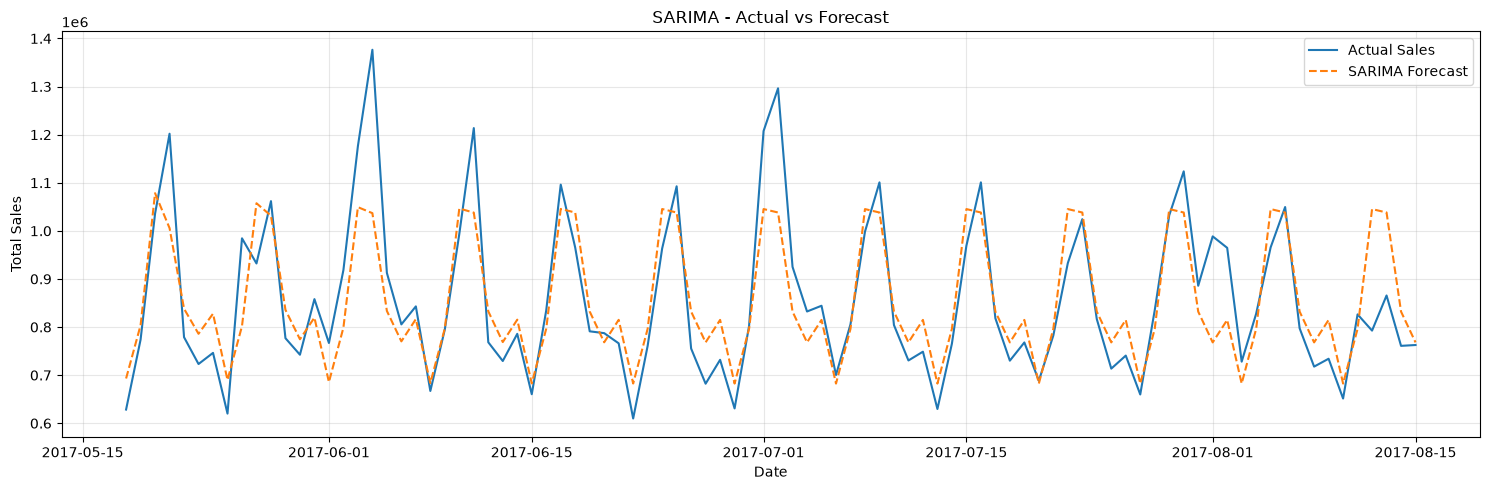

In [51]:

from statsmodels.tsa.statespace.sarimax import SARIMAX

# Build SARIMA Model
sarima_model = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Fit model
sarima_result = sarima_model.fit(
    disp=False,
    maxiter=100
)

# Forecast next 90 days
sarima_forecast = sarima_result.forecast(
    steps=len(test)
)

# Model Evaluation
sarima_mae = mean_absolute_error(
    test, sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(test, sarima_forecast)
)

print("SARIMA Model Evaluation")
print(f"MAE: {sarima_mae:,.2f}")
print(f"RMSE: {sarima_rmse:,.2f}")
print("Converged:",
      sarima_result.mle_retvals.get("converged"))

# Compare Models
comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "ARIMA(1,1,1)",
        "SARIMA(1,0,1)(1,1,1,7)"
    ],
    "MAE": [
        baseline_mae,
        arima_mae,
        sarima_mae
    ],
    "RMSE": [
        baseline_rmse,
        arima_rmse,
        sarima_rmse
    ]
})

display(comparison.round(2))

# Actual vs Forecast
plt.figure(figsize=(15, 5))

plt.plot(
    test.index,
    test,
    label="Actual Sales"
)

plt.plot(
    sarima_forecast.index,
    sarima_forecast,
    label="SARIMA Forecast",
    linestyle="--"
)

plt.title("SARIMA - Actual vs Forecast")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Key Findings
- SARIMA(1,0,1)(1,1,1,7) menghasilkan MAE sebesar 67.465,06 dan RMSE sebesar 90.514,69.
- SARIMA menjadi model terbaik sementara dibandingkan Seasonal Naive dan ARIMA(1,1,1).
- Dibandingkan Seasonal Naive, SARIMA berhasil menurunkan MAE sebesar 27,82% dan RMSE sebesar 30,80%.
- SARIMA mampu mengikuti pola weekly seasonality dengan lebih baik dibandingkan ARIMA.
- Beberapa lonjakan penjualan ekstrem masih belum berhasil diprediksi secara akurat.
- Model berhasil mencapai konvergensi dan akan dievaluasi lebih lanjut melalui residual diagnostics serta parameter tuning.


### 5.5 SARIMA Residual Diagnostics

Ljung-Box Test:


,lb_stat,lb_pvalue
7,9.624435,2.108739e-01
14,56.225226,5.325959e-07
21,117.051233,2.473916e-15
28,136.954537,2.619389e-16



D'Agostino-Pearson Test:
Statistic: 969.7469
P-value: 0.000000


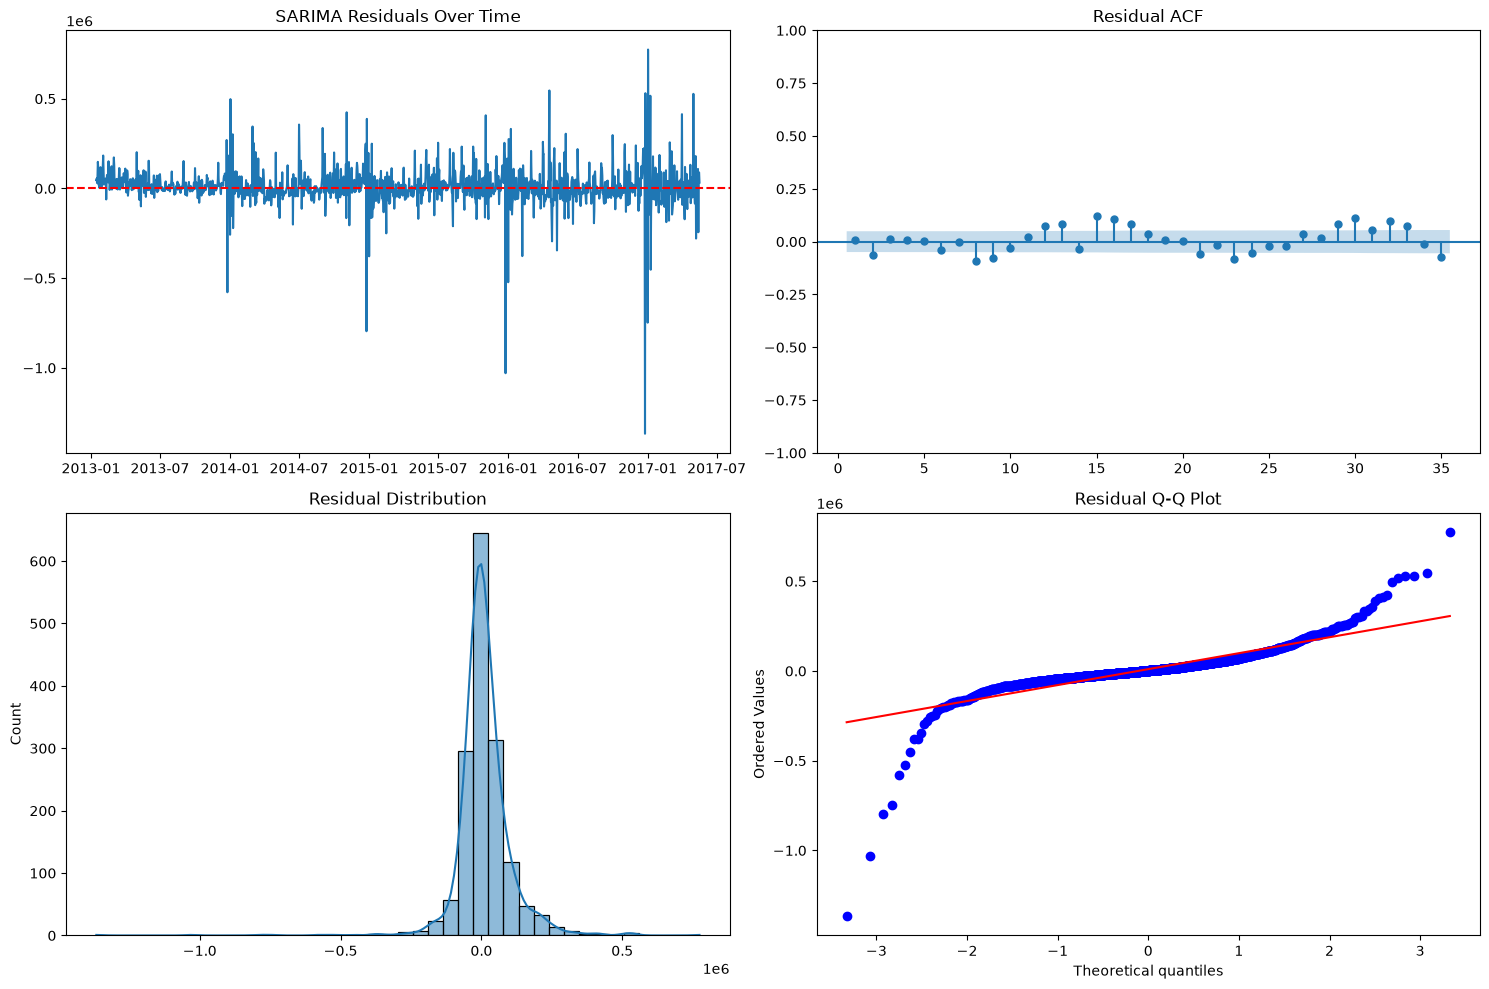

In [56]:

from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import normaltest, probplot

# Extract SARIMA training residuals
residuals = sarima_result.resid.iloc[14:].dropna()

# Ljung-Box Test
ljung_box = acorr_ljungbox(
    residuals,
    lags=[7, 14, 21, 28],
    return_df=True
)

print("Ljung-Box Test:")
display(ljung_box)

# D'Agostino-Pearson Normality Test
stat, p_value = normaltest(residuals)

print("\nD'Agostino-Pearson Test:")
print(f"Statistic: {stat:.4f}")
print(f"P-value: {p_value:.6f}")

# Residual Visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Residual Time Series
axes[0, 0].plot(residuals)
axes[0, 0].axhline(0, color="red", linestyle="--")
axes[0, 0].set_title("SARIMA Residuals Over Time")

# Residual ACF
plot_acf(
    residuals,
    lags=35,
    zero=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Residual ACF")

# Residual Distribution
sns.histplot(
    residuals,
    bins=40,
    kde=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Residual Distribution")

# Q-Q Plot
probplot(
    residuals,
    dist="norm",
    plot=axes[1, 1]
)
axes[1, 1].set_title("Residual Q-Q Plot")

plt.tight_layout()
plt.show()



### Key Findings
- Ljung-Box Test pada lag 7 menghasilkan p-value 0,2109, sehingga tidak ditemukan bukti autokorelasi residual yang signifikan hingga lag tersebut.
- Pada lag 14, 21, dan 28, p-value < 0,05 menunjukkan masih terdapat autokorelasi residual yang signifikan.
- D'Agostino-Pearson Test menghasilkan statistic 969,7469 dengan p-value < 0,05, sehingga residual tidak berdistribusi normal.
- Histogram residual menunjukkan konsentrasi tinggi di sekitar nol dengan beberapa nilai ekstrem.
- Q-Q Plot menunjukkan penyimpangan pada kedua ekor distribusi (heavy tails).
- Model SARIMA telah menangkap sebagian besar pola mingguan, tetapi masih terdapat struktur residual yang belum sepenuhnya dijelaskan.
- Diperlukan evaluasi konfigurasi parameter untuk meningkatkan kualitas model forecasting.


### 5.6 SARIMA Hyperparameter Tuning

In [57]:

# Split training data into inner training and validation
train_inner = train.iloc[:-90]
validation = train.iloc[-90:]

# Define SARIMA candidates
candidates = {
    "SARIMA A": ((1, 0, 1), (1, 1, 1, 7)),
    "SARIMA B": ((1, 0, 1), (0, 1, 1, 7)),
    "SARIMA C": ((1, 1, 1), (1, 0, 1, 7)),
    "SARIMA D": ((2, 0, 1), (1, 1, 0, 7))
}

results = []

for name, (order, seasonal_order) in candidates.items():

    print(f"Testing {name}...")

    try:
        model = SARIMAX(
            train_inner,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted = model.fit(
            disp=False,
            maxiter=80
        )

        forecast = fitted.forecast(
            steps=len(validation)
        )

        mae = mean_absolute_error(
            validation, forecast
        )

        rmse = np.sqrt(
            mean_squared_error(validation, forecast)
        )

        results.append({
            "Model": name,
            "Order": str(order),
            "Seasonal Order": str(seasonal_order),
            "MAE": mae,
            "RMSE": rmse,
            "AIC": fitted.aic,
            "Converged": fitted.mle_retvals.get("converged")
        })

    except Exception as e:
        print(f"{name} failed: {e}")

# Compare model performance
tuning_results = pd.DataFrame(results)

if not tuning_results.empty:
    tuning_results = tuning_results.sort_values(
        by=["MAE", "RMSE"]
    ).reset_index(drop=True)

    display(tuning_results.round(2))


Testing SARIMA A...
Testing SARIMA B...
Testing SARIMA C...
Testing SARIMA D...


,Model,Order,Seasonal Order,MAE,RMSE,AIC,Converged
0,SARIMA B,"(1, 0, 1)","(0, 1, 1, 7)",69101.70,106863.38,38824.14,True
1,SARIMA A,"(1, 0, 1)","(1, 1, 1, 7)",69127.81,108764.87,38752.76,True
2,SARIMA D,"(2, 0, 1)","(1, 1, 0, 7)",77456.93,119909.36,39026.22,True
3,SARIMA C,"(1, 1, 1)","(1, 0, 1, 7)",81336.77,121190.18,39372.56,True



### Key Findings
- Hyperparameter tuning dilakukan terhadap 4 konfigurasi SARIMA menggunakan validation set sebanyak 90 hari.
- SARIMA B (1,0,1)(0,1,1,7) menghasilkan performa validation terbaik dengan MAE 69.101,70 dan RMSE 106.863,38.
- Selisih MAE antara SARIMA B dan SARIMA A hanya sekitar 0,04%, menunjukkan performa prediksi yang hampir setara.
- SARIMA A memiliki AIC terendah sebesar 38.752,76, sedangkan SARIMA B sebesar 38.824,14.
- Seluruh konfigurasi berhasil mencapai konvergensi.
- SARIMA B dipilih sebagai kandidat model final berdasarkan MAE dan RMSE validation terendah, dengan SARIMA A sebagai model pembanding.


### 5.7 SARIMA Model Evaluation

Final SARIMA Model Evaluation
MAE: 66,643.39
RMSE: 88,695.36
Converged: True


,Model,MAE,RMSE
3,SARIMA B,66643.39,88695.36
2,SARIMA A,67465.06,90514.69
0,Seasonal Naive,93467.95,130808.95
1,"ARIMA(1,1,1)",134816.03,164138.51


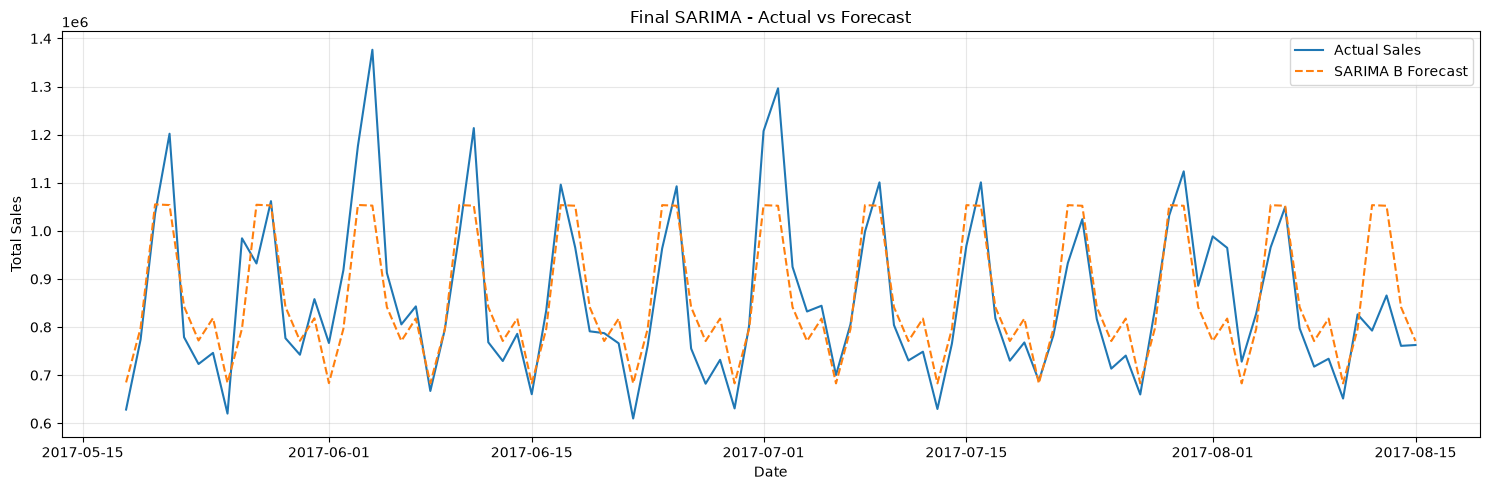

In [58]:

# Build selected SARIMA Model
final_model = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(0, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Fit model
final_result = final_model.fit(
    disp=False,
    maxiter=100
)

# Forecast testing period
final_forecast = final_result.forecast(
    steps=len(test)
)

# Calculate evaluation metrics
final_mae = mean_absolute_error(
    test, final_forecast
)

final_rmse = np.sqrt(
    mean_squared_error(test, final_forecast)
)

print("Final SARIMA Model Evaluation")
print(f"MAE: {final_mae:,.2f}")
print(f"RMSE: {final_rmse:,.2f}")
print("Converged:",
      final_result.mle_retvals.get("converged"))

# Compare all models
final_comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "ARIMA(1,1,1)",
        "SARIMA A",
        "SARIMA B"
    ],
    "MAE": [
        baseline_mae,
        arima_mae,
        sarima_mae,
        final_mae
    ],
    "RMSE": [
        baseline_rmse,
        arima_rmse,
        sarima_rmse,
        final_rmse
    ]
})

display(
    final_comparison.sort_values("MAE").round(2)
)

# Visualize Actual vs Forecast
plt.figure(figsize=(15, 5))

plt.plot(
    test.index,
    test,
    label="Actual Sales"
)

plt.plot(
    final_forecast.index,
    final_forecast,
    label="SARIMA B Forecast",
    linestyle="--"
)

plt.title("Final SARIMA - Actual vs Forecast")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [59]:
%pip install prophet


   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
    --------------------------------------- 0.3/12.1 MB ? eta -:--:--
    --------------------------------------- 0.3/12.1 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.1 MB 681.2 kB/s eta 0:00:18
   -- ------------------------------------- 0.8/12.1 MB 889.3 kB/s eta 0:00:13
   --- ------------------------------------ 1.0/12.1 MB 995.6 kB/s eta 0:00:12
   ----- ---------------------------------- 1.6/12.1 MB 1.2 MB/s eta 0:00:09
   ------ --------------------------------- 1.8/12.1 MB 1.3 MB/s eta 0:00:08
   ------ --------------------------------- 2.1/12.1 MB 1.3 MB/s eta 0:00:08
   -------- ------------------------------- 2.6/12.1 MB 1.4 MB/s eta 0:00:07
   --------- ------------------------------ 2.9/12.1 MB 1.4 MB/s eta 0:00:07
   ---------- ----------------------------- 3.1/12.1 MB 1.4 MB/s eta 0:00:07
   ---------- -------

In [60]:
from prophet import Prophet

### 5.8 Prophet Forecasting

20:06:36 - cmdstanpy - INFO - Chain [1] start processing
20:06:37 - cmdstanpy - INFO - Chain [1] done processing


Prophet Validation Evaluation
MAE: 84,051.96
RMSE: 127,118.81


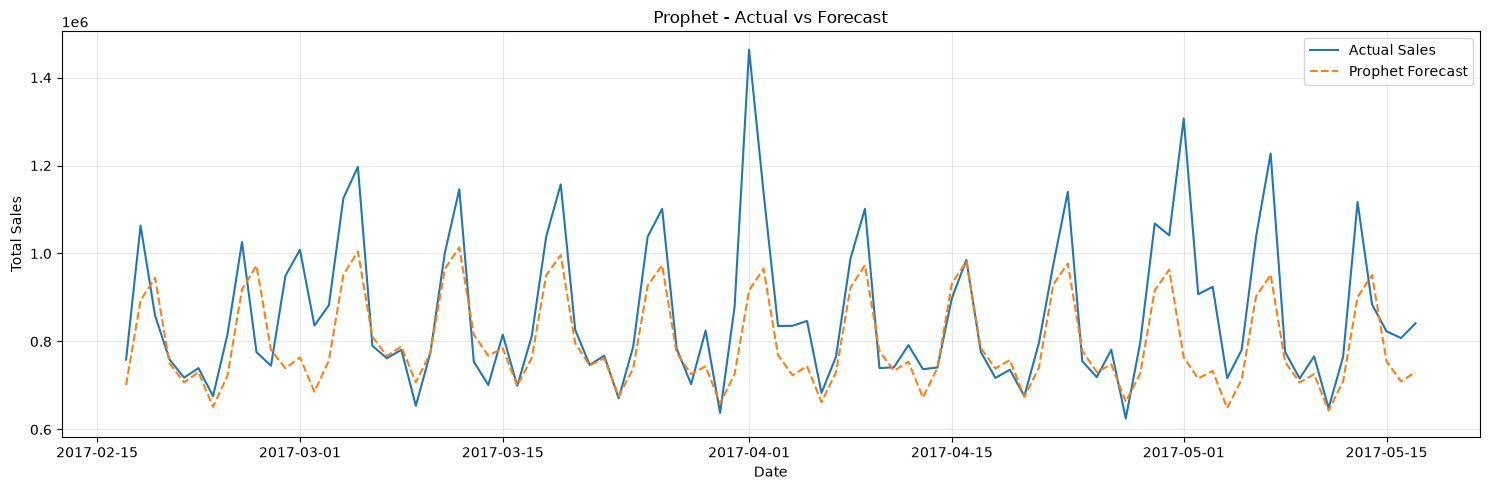

In [61]:

from prophet import Prophet

# Prepare Prophet dataset
prophet_train = train_inner.reset_index()
prophet_train.columns = ["ds", "y"]

prophet_validation = validation.reset_index()
prophet_validation.columns = ["ds", "y"]

# Build Prophet Model
prophet_model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False
)

# Fit Model
prophet_model.fit(prophet_train)

# Predict validation period
prophet_prediction = prophet_model.predict(
    prophet_validation[["ds"]]
)

# Extract forecast
prophet_forecast = prophet_prediction["yhat"].values

# Model Evaluation
prophet_mae = mean_absolute_error(
    validation, prophet_forecast
)

prophet_rmse = np.sqrt(
    mean_squared_error(validation, prophet_forecast)
)

print("Prophet Validation Evaluation")
print(f"MAE: {prophet_mae:,.2f}")
print(f"RMSE: {prophet_rmse:,.2f}")

# Visualization
plt.figure(figsize=(15, 5))

plt.plot(
    validation.index,
    validation,
    label="Actual Sales"
)

plt.plot(
    validation.index,
    prophet_forecast,
    label="Prophet Forecast",
    linestyle="--"
)

plt.title("Prophet - Actual vs Forecast")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Key Findings
- Prophet menghasilkan MAE sebesar 84.051,96 dan RMSE sebesar 127.118,81 pada validation set.
- Prophet mampu menangkap pola weekly seasonality, tetapi masih mengalami underprediction pada beberapa lonjakan penjualan.
- Forecast Prophet cenderung lebih halus dibandingkan fluktuasi penjualan aktual.
- Performa Prophet masih lebih rendah dibandingkan SARIMA A dan SARIMA B berdasarkan MAE dan RMSE validation.
- SARIMA B tetap menjadi kandidat model terbaik sementara.
- Penambahan holiday effects berpotensi meningkatkan kemampuan Prophet dalam menangkap pola penjualan pada tanggal khusus.


### 5.9 Simple Exponential Smoothing (SES)

SES Validation Evaluation
MAE: 125,396.08
RMSE: 176,200.59


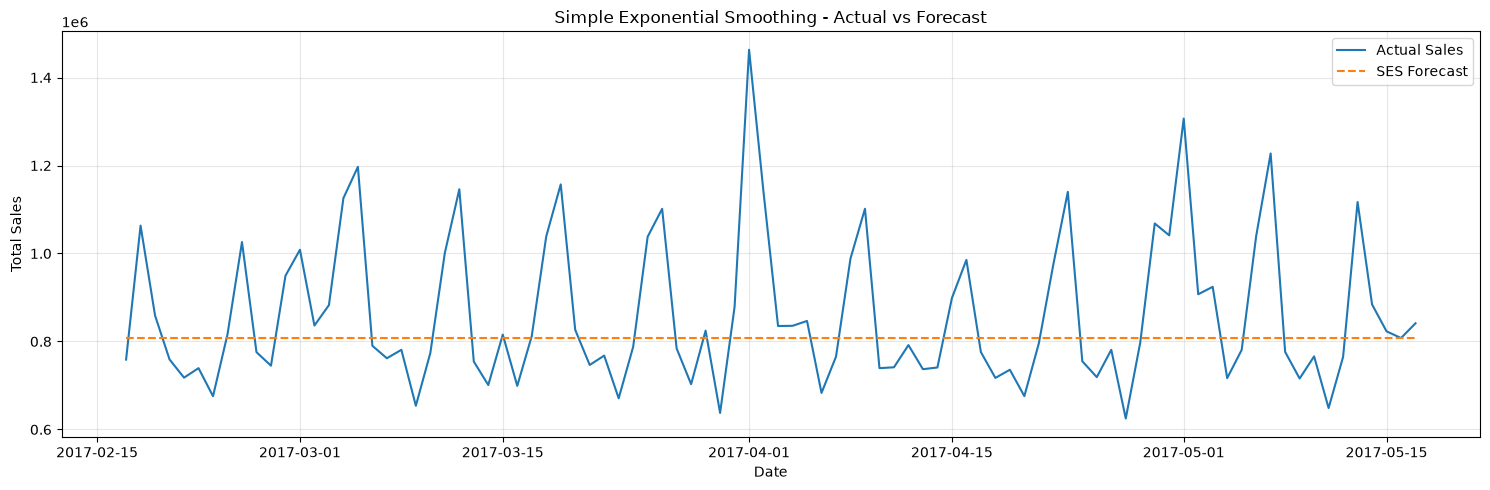

In [62]:

from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Build SES Model
ses_model = SimpleExpSmoothing(
    train_inner,
    initialization_method="estimated"
)

# Fit Model
ses_result = ses_model.fit(
    optimized=True
)

# Forecast Validation Period
ses_forecast = ses_result.forecast(
    steps=len(validation)
)

# Model Evaluation
ses_mae = mean_absolute_error(
    validation, ses_forecast
)

ses_rmse = np.sqrt(
    mean_squared_error(validation, ses_forecast)
)

print("SES Validation Evaluation")
print(f"MAE: {ses_mae:,.2f}")
print(f"RMSE: {ses_rmse:,.2f}")

# Visualization
plt.figure(figsize=(15, 5))

plt.plot(
    validation.index,
    validation,
    label="Actual Sales"
)

plt.plot(
    ses_forecast.index,
    ses_forecast,
    label="SES Forecast",
    linestyle="--"
)

plt.title("Simple Exponential Smoothing - Actual vs Forecast")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Key Findings
- SES menghasilkan MAE sebesar 125.396,08 dan RMSE sebesar 176.200,59 pada validation set.
- Forecast SES cenderung konstan karena model hanya memperhitungkan level penjualan tanpa trend dan seasonality secara eksplisit.
- SES belum mampu mengikuti pola fluktuasi mingguan maupun lonjakan penjualan ekstrem.
- Performa SES lebih rendah dibandingkan SARIMA B dan Prophet berdasarkan MAE dan RMSE validation.
- Hasil ini menunjukkan pentingnya mempertimbangkan seasonality dalam pengembangan model forecasting.


### 5.10 Holt-Winters Seasonal Forecasting

Holt-Winters Validation Evaluation
MAE: 73,568.09
RMSE: 114,414.16


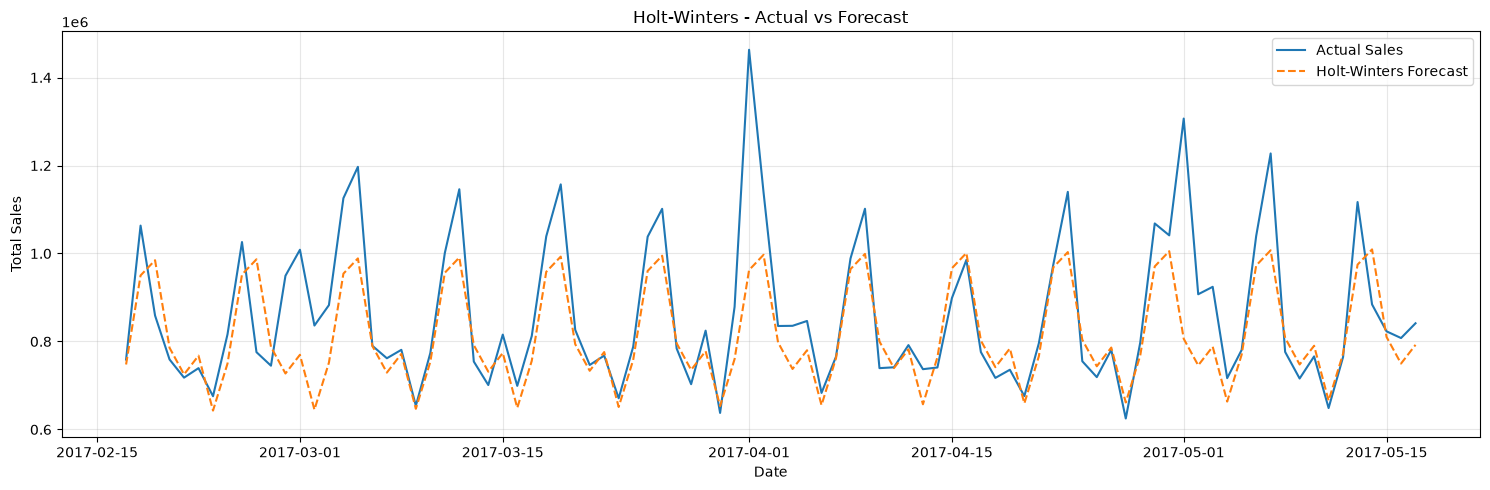

In [64]:

from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Build Holt-Winters Model
hw_model = ExponentialSmoothing(
    train_inner,
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
)

# Fit Model
hw_result = hw_model.fit(
    optimized=True
)

# Forecast Validation Period
hw_forecast = hw_result.forecast(
    steps=len(validation)
)

# Model Evaluation
hw_mae = mean_absolute_error(
    validation, hw_forecast
)

hw_rmse = np.sqrt(
    mean_squared_error(validation, hw_forecast)
)

print("Holt-Winters Validation Evaluation")
print(f"MAE: {hw_mae:,.2f}")
print(f"RMSE: {hw_rmse:,.2f}")

# Visualization
plt.figure(figsize=(15, 5))

plt.plot(
    validation.index,
    validation,
    label="Actual Sales"
)

plt.plot(
    hw_forecast.index,
    hw_forecast,
    label="Holt-Winters Forecast",
    linestyle="--"
)

plt.title("Holt-Winters - Actual vs Forecast")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Key Findings
- Holt-Winters menghasilkan MAE sebesar 73.568,09 dan RMSE sebesar 114.414,16 pada validation set.
- Model mampu mengikuti pola weekly seasonality dengan lebih baik dibandingkan SES.
- Dibandingkan SES, Holt-Winters berhasil menurunkan MAE sekitar 41,3%.
- Beberapa lonjakan penjualan ekstrem masih mengalami underprediction.
- Holt-Winters menunjukkan performa lebih baik dibandingkan Prophet dan SES, tetapi masih berada di bawah SARIMA B.
- Hasil ini semakin mendukung pentingnya komponen seasonality dalam forecasting penjualan retail.


### 5.11 Final Model Comparison (Validation)

Validation Model Comparison:


,Model,MAE,RMSE
0,SARIMA B,69101.70,106863.38
1,Holt-Winters,73568.09,114414.16
2,Prophet,84051.96,127118.81
3,Seasonal Naive,86366.03,127083.17
4,SES,125396.08,176200.59
5,ARIMA,128234.77,170066.90


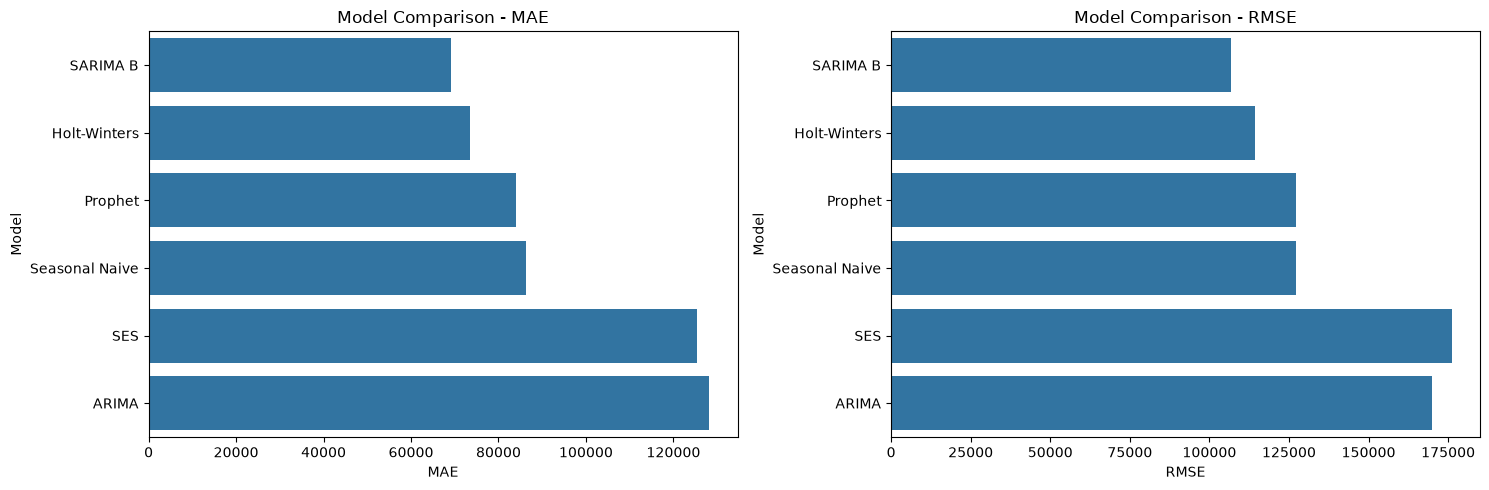

In [65]:

# Seasonal Naive - Validation
naive_val = np.tile(
    train_inner.iloc[-7:].values,
    int(np.ceil(len(validation) / 7))
)[:len(validation)]

# ARIMA - Validation
arima_val_model = ARIMA(
    train_inner,
    order=(1, 1, 1)
)

arima_val_result = arima_val_model.fit()

arima_val_forecast = arima_val_result.forecast(
    steps=len(validation)
)

# Collect validation predictions
validation_models = {
    "Seasonal Naive": naive_val,
    "ARIMA": arima_val_forecast,
    "Prophet": prophet_forecast,
    "SES": ses_forecast,
    "Holt-Winters": hw_forecast
}

results = []

for name, pred in validation_models.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(validation, pred),
        "RMSE": np.sqrt(
            mean_squared_error(validation, pred)
        )
    })

# Add SARIMA B from previous tuning
sarima_b = tuning_results[
    tuning_results["Model"] == "SARIMA B"
].iloc[0]

results.append({
    "Model": "SARIMA B",
    "MAE": sarima_b["MAE"],
    "RMSE": sarima_b["RMSE"]
})

# Compare all 6 models
model_comparison = pd.DataFrame(results)

model_comparison = model_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

print("Validation Model Comparison:")
display(model_comparison.round(2))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=model_comparison,
    x="MAE",
    y="Model",
    ax=axes[0]
)

axes[0].set_title("Model Comparison - MAE")

sns.barplot(
    data=model_comparison,
    x="RMSE",
    y="Model",
    ax=axes[1]
)

axes[1].set_title("Model Comparison - RMSE")

plt.tight_layout()
plt.show()



### Key Findings
- Evaluasi dilakukan terhadap 6 jenis model forecasting menggunakan validation set yang sama selama 90 hari.
- SARIMA B (1,0,1)(0,1,1,7) menghasilkan performa terbaik dengan MAE 69.101,70 dan RMSE 106.863,38.
- Holt-Winters menempati posisi kedua dengan MAE 73.568,09, diikuti Prophet dengan MAE 84.051,96.
- Dibandingkan Seasonal Naive, SARIMA B berhasil menurunkan MAE sebesar 19,99%.
- SES dan ARIMA menunjukkan performa lebih rendah karena konfigurasi yang digunakan belum mampu menangkap weekly seasonality secara efektif.
- Hasil perbandingan menunjukkan bahwa model dengan komponen seasonal cenderung menghasilkan forecasting yang lebih akurat pada dataset ini.
- SARIMA B dipilih sebagai model terbaik berdasarkan validation performance dan telah menunjukkan hasil yang baik pada testing set.


### 5.12 Final SARIMA Residual Diagnostics

Ljung-Box Test:


,lb_stat,lb_pvalue
7,74.933631,1.479322e-13
14,126.502333,3.326327e-20
21,173.269970,6.003745e-26
28,187.547319,1.518303e-25



D'Agostino-Pearson Test:
Statistic: 1112.1416
P-value: 0.000000
Mean Residual: 7,050.62


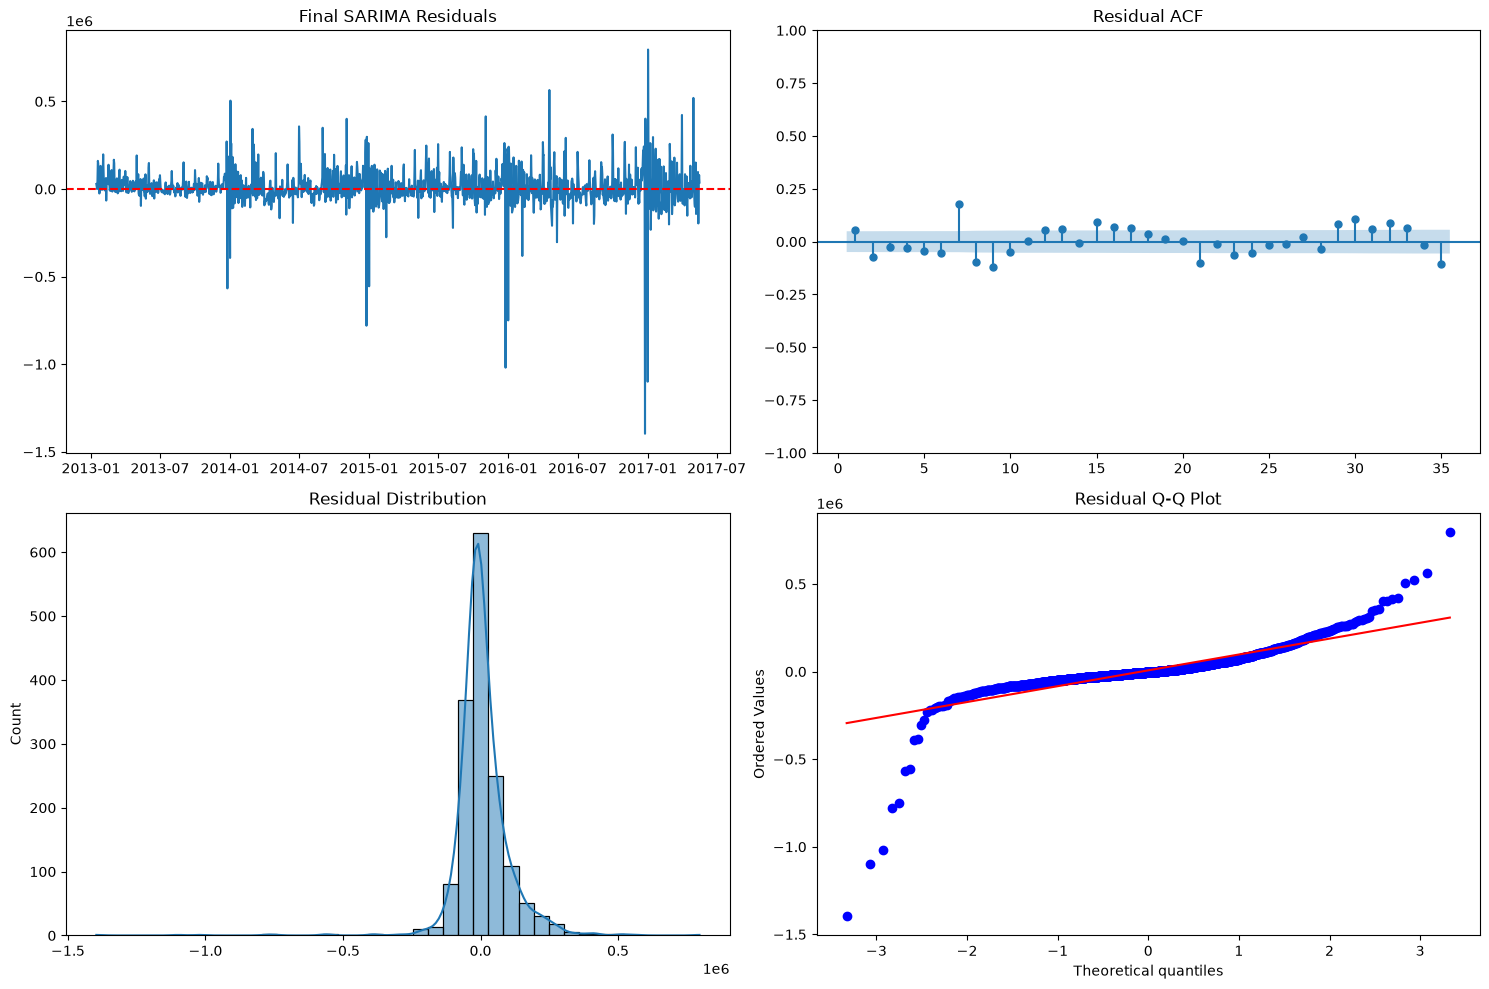

In [66]:

from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from scipy.stats import normaltest, probplot

# Extract final SARIMA B residuals
final_residuals = final_result.resid.iloc[14:].dropna()

# Ljung-Box Test
lb_test = acorr_ljungbox(
    final_residuals,
    lags=[7, 14, 21, 28],
    return_df=True
)

print("Ljung-Box Test:")
display(lb_test)

# D'Agostino-Pearson Normality Test
stat, p_value = normaltest(final_residuals)

print("\nD'Agostino-Pearson Test:")
print(f"Statistic: {stat:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Mean Residual: {final_residuals.mean():,.2f}")

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Residual Time Series
axes[0, 0].plot(final_residuals)
axes[0, 0].axhline(0, color="red", linestyle="--")
axes[0, 0].set_title("Final SARIMA Residuals")

# Residual ACF
plot_acf(
    final_residuals,
    lags=35,
    zero=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Residual ACF")

# Residual Distribution
sns.histplot(
    final_residuals,
    bins=40,
    kde=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Residual Distribution")

# Q-Q Plot
probplot(
    final_residuals,
    dist="norm",
    plot=axes[1, 1]
)
axes[1, 1].set_title("Residual Q-Q Plot")

plt.tight_layout()
plt.show()



### Key Findings
- Ljung-Box Test menghasilkan p-value < 0,05 pada lag 7, 14, 21, dan 28, menunjukkan masih terdapat autokorelasi residual yang signifikan.
- D'Agostino-Pearson Test menghasilkan statistic 1.112,1416 dengan p-value < 0,05, sehingga residual tidak berdistribusi normal.
- Mean residual sebesar 7.050,62 menunjukkan rata-rata residual belum sepenuhnya berada di sekitar nol.
- Residual ACF memperlihatkan beberapa lag signifikan yang belum sepenuhnya ditangkap model.
- Beberapa residual ekstrem masih ditemukan, terutama pada periode pergantian tahun.
- Meskipun residual diagnostics belum ideal, SARIMA B tetap menghasilkan MAE dan RMSE terendah dibandingkan model lainnya.
- SARIMA B dipilih sebagai model final berdasarkan akurasi forecasting, dengan autokorelasi residual dan nilai ekstrem sebagai keterbatasan model.


### 5.13 Final Sales Forecasting

Forecast Period:
2017-08-16 00:00:00 to 2017-11-13 00:00:00

Forecast Summary:


,Forecast,Lower_CI,Upper_CI
count,90.00,90.00,90.00
mean,837328.63,520259.73,1154397.54
std,130081.49,129664.93,134005.59
min,622337.53,318307.83,872611.02
25%,766012.02,451229.56,1080651.78
50%,803226.08,480091.22,1122499.64
75%,983607.23,653474.77,1291726.36
max,1066161.22,768562.11,1409005.86



First 5 Forecasts:


,Forecast,Lower_CI,Upper_CI
2017-08-16,745522.27,506907.17,984137.38
2017-08-17,622337.53,372064.05,872611.02
2017-08-18,770150.29,511067.89,1029232.68
2017-08-19,956846.04,691034.38,1222657.71
2017-08-20,1039553.66,768562.11,1310545.20


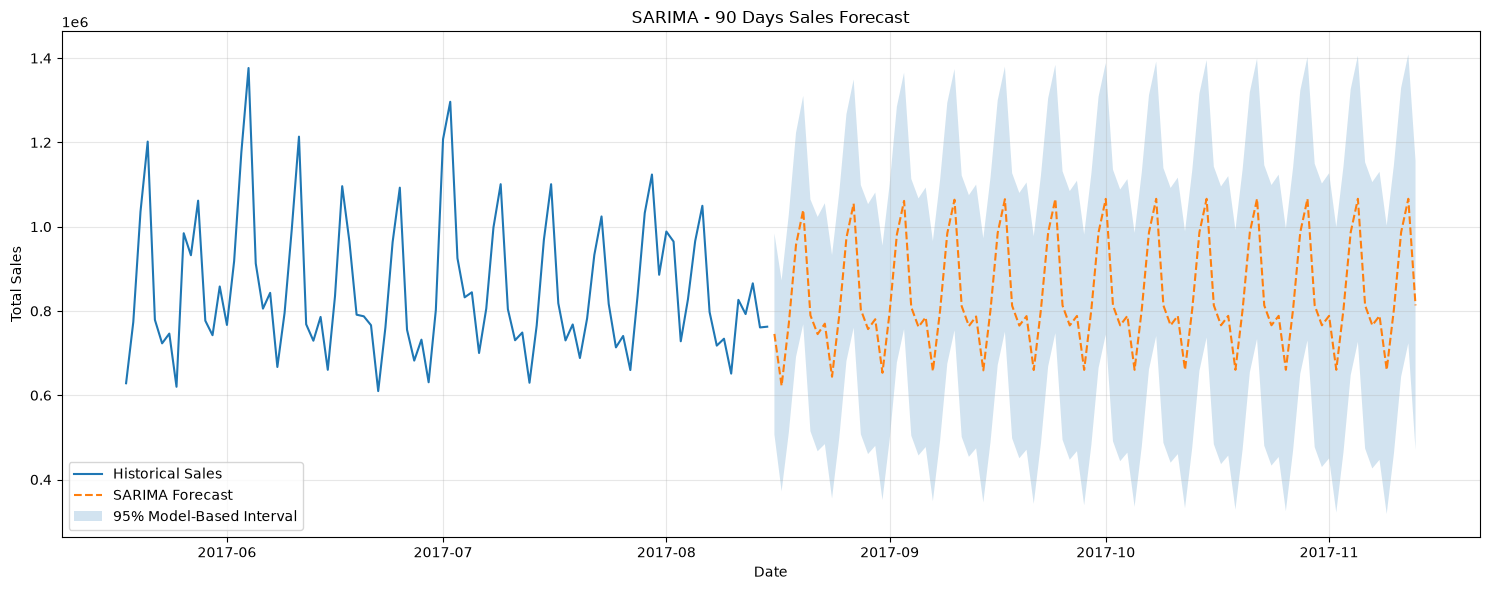

In [67]:

# Refit SARIMA using all historical data
forecast_model = SARIMAX(
    df_ts["total_sales"],
    order=(1, 0, 1),
    seasonal_order=(0, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

forecast_result = forecast_model.fit(
    disp=False,
    maxiter=100
)

# Forecast next 90 days
forecast_output = forecast_result.get_forecast(
    steps=90
)

# Extract forecast and confidence intervals
future_forecast = forecast_output.predicted_mean
confidence_interval = forecast_output.conf_int(
    alpha=0.05
)

# Create forecast dataset
df_future = pd.DataFrame({
    "Forecast": future_forecast,
    "Lower_CI": confidence_interval.iloc[:, 0],
    "Upper_CI": confidence_interval.iloc[:, 1]
})

print("Forecast Period:")
print(df_future.index.min(), "to",
      df_future.index.max())

print("\nForecast Summary:")
display(df_future.describe().round(2))

print("\nFirst 5 Forecasts:")
display(df_future.head().round(2))

# Visualization
plt.figure(figsize=(15, 6))

# Last 90 days of actual sales
plt.plot(
    df_ts.index[-90:],
    df_ts["total_sales"].iloc[-90:],
    label="Historical Sales"
)

# Forecast
plt.plot(
    df_future.index,
    df_future["Forecast"],
    label="SARIMA Forecast",
    linestyle="--"
)

# Confidence Interval
plt.fill_between(
    df_future.index,
    df_future["Lower_CI"],
    df_future["Upper_CI"],
    alpha=0.2,
    label="95% Model-Based Interval"
)

plt.title("SARIMA - 90 Days Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Key Findings
- SARIMA B menghasilkan forecasting untuk periode 16 Agustus hingga 13 November 2017 dengan horizon 90 hari.
- Rata-rata prediksi penjualan harian sebesar 837.328,63, dengan nilai minimum 622.337,53 dan maksimum 1.066.161,22.
- Forecast menunjukkan pola weekly seasonality yang konsisten dengan hasil analisis sebelumnya.
- Prediksi penjualan cenderung stabil tanpa perubahan tren yang signifikan selama periode forecasting.
- Interval prediksi 95% menunjukkan adanya ketidakpastian yang cukup besar terhadap nilai penjualan aktual.
- Model belum sepenuhnya menangkap pengaruh holiday effects dan fluktuasi ekstrem, sehingga hasil forecasting perlu digunakan dengan mempertimbangkan keterbatasan tersebut.


In [ ]:
### 5.14 Export Dataset for Power BI

In [74]:

import os

# 1. Export Historical Sales Detail
df_clean.to_csv(
    "historical_sales_detail.csv",
    index=False
)

# 2. Prepare Historical Daily Sales
actual_export = pd.DataFrame({
    "Date": df_ts.index,
    "Actual_Sales": df_ts["total_sales"].values,
    "OnPromotion": df_ts["total_onpromotion"].values,
    "Is_Assumed_Holiday": df_ts["is_assumed_holiday"].values,
    "Period": "Historical",
    "Forecast_Sales": np.nan,
    "Lower_CI": np.nan,
    "Upper_CI": np.nan
})

# 3. Prepare Future Forecast
future_export = pd.DataFrame({
    "Date": df_future.index,
    "Actual_Sales": np.nan,
    "OnPromotion": np.nan,
    "Is_Assumed_Holiday": False,
    "Period": "Forecast",
    "Forecast_Sales": df_future["Forecast"].values,
    "Lower_CI": df_future["Lower_CI"].values,
    "Upper_CI": df_future["Upper_CI"].values
})

# 4. Combine Historical and Forecast
df_dashboard = pd.concat(
    [actual_export, future_export],
    ignore_index=True
).sort_values("Date")

df_dashboard.to_csv(
    "daily_sales_forecast.csv",
    index=False
)

# 5. Export Model Comparison (Validation)
model_comparison.to_csv(
    "model_comparison.csv",
    index=False
)

# 6. Validate Export
print("CSV Files Successfully Exported!")

print("\nHistorical Detail:", df_clean.shape)
print("Daily Sales & Forecast:", df_dashboard.shape)
print("Model Comparison:", model_comparison.shape)

print("\nSaved Folder:")
print(os.getcwd())

print("\nDaily Forecast Preview:")
display(df_dashboard.tail(10))


CSV Files Successfully Exported!

Historical Detail: (3000888, 6)
Daily Sales & Forecast: (1778, 8)
Model Comparison: (6, 3)

Saved Folder:
C:\Users\rabat

Daily Forecast Preview:


,Date,Actual_Sales,OnPromotion,Is_Assumed_Holiday,Period,Forecast_Sales,Lower_CI,Upper_CI
1768,2017-11-04,NaN,NaN,False,Forecast,9.868330e+05,647527.525652,1.326138e+06
1769,2017-11-05,NaN,NaN,False,Forecast,1.066160e+06,726666.947220,1.405652e+06
1770,2017-11-06,NaN,NaN,False,Forecast,8.132312e+05,473591.050388,1.152871e+06
1771,2017-11-07,NaN,NaN,False,Forecast,7.660321e+05,426276.009070,1.105788e+06
1772,2017-11-08,NaN,NaN,False,Forecast,7.884575e+05,446714.220914,1.130201e+06
1773,2017-11-09,NaN,NaN,False,Forecast,6.604320e+05,318307.825985,1.002556e+06
1774,2017-11-10,NaN,NaN,False,Forecast,8.039497e+05,461526.048063,1.146373e+06
1775,2017-11-11,NaN,NaN,False,Forecast,9.868347e+05,644175.434282,1.329494e+06
1776,2017-11-12,NaN,NaN,False,Forecast,1.066161e+06,723316.573440,1.409006e+06
1777,2017-11-13,NaN,NaN,False,Forecast,8.132325e+05,470242.007389,1.156223e+06
